In [98]:
# IMPORTS

from pacha.utils import file_utils as futils
import os
from pacha.L2_processing import radar as l2rad
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd

from pacha.utils import instruments as iutils
from pacha.utils import scores as sutils
from pacha.visualisation import geospatial as gvis
from pacha.utils import geospatial as gutils

import numpy as np
import xarray as xr
import dask.array as da
from scipy.spatial import cKDTree, ConvexHull, Delaunay
from pyproj import CRS, Geod, Transformer
import pandas as pd



In [4]:
def to_lonlat(ds, resolution_m=400, variable="dBZ"):
    """
    Convert variable(time, i, j) to variable(time, lat, lon).

    For a complete circular coordinate grid like test_day.nc.
    Uses nearest-gate sampling, preserves NaNs, and returns lazy data.
    """
    if not np.isfinite(resolution_m) or resolution_m <= 0:
        raise ValueError("resolution_m must be positive and finite.")

    lon = np.asarray(ds.xlon.values, dtype=float)
    lat = np.asarray(ds.ylat.values, dtype=float)
    spatial_dims = ds.xlon.dims

    if (
        lon.ndim != 2
        or lon.shape != lat.shape
        or ds.ylat.dims != spatial_dims
    ):
        raise ValueError("Expected matching static 2-D xlon/ylat.")

    if not (np.isfinite(lon).all() and np.isfinite(lat).all()):
        raise ValueError("This method requires complete geographic coordinates.")

    if set(ds[variable].dims) != {"time", *spatial_dims}:
        raise ValueError("Expected time and two native spatial dimensions.")

    if not np.issubdtype(ds[variable].dtype, np.floating):
        raise TypeError("The variable must have a floating dtype.")

    # Degree spacing corresponding to resolution_m near the radar.
    lon0, lat0 = float(np.median(lon)), float(np.median(lat))
    geod = Geod(ellps="WGS84")
    _, _, dx = geod.inv(lon0, lat0, lon0 + 0.01, lat0)
    _, _, dy = geod.inv(lon0, lat0, lon0, lat0 + 0.01)

    dlon = resolution_m / (dx / 0.01)
    dlat = resolution_m / (dy / 0.01)

    out_lon = lon.min() + np.arange(int(np.ptp(lon) / dlon) + 1) * dlon
    out_lat = lat.min() + np.arange(int(np.ptp(lat) / dlat) + 1) * dlat
    ny, nx = len(out_lat), len(out_lon)

    if ny * nx > 25_000_000:
        raise ValueError("Target grid is too large; increase resolution_m.")

    # Find nearest gates using distances in metres.
    local_crs = CRS.from_proj4(
        f"+proj=aeqd +lat_0={lat0} +lon_0={lon0} "
        "+datum=WGS84 +units=m"
    )
    project = Transformer.from_crs(
        "EPSG:4326", local_crs, always_xy=True
    )

    sx, sy = project.transform(lon.ravel(), lat.ravel())
    source_points = np.column_stack([sx, sy])

    target_lon, target_lat = np.meshgrid(out_lon, out_lat)
    tx, ty = project.transform(target_lon.ravel(), target_lat.ravel())
    target_points = np.column_stack([tx, ty])

    _, nearest = cKDTree(source_points).query(target_points)

    # Mask points outside the radar footprint.
    hull = ConvexHull(source_points)
    inside = (
        Delaunay(source_points[hull.vertices])
        .find_simplex(target_points) >= 0
    )

    # Read native time chunks, then remap one timestep per block.
    field = ds[variable].transpose("time", *spatial_dims)
    native_chunks = field.encoding.get("chunksizes")
    read_chunk = native_chunks[0] if native_chunks else 1

    data = field.chunk({
        "time": read_chunk,
        spatial_dims[0]: -1,
        spatial_dims[1]: -1,
    }).data.rechunk({0: 1})

    def remap(block):
        values = block.reshape(block.shape[0], -1)[:, nearest].copy()
        values[:, ~inside] = np.nan
        return values.reshape(block.shape[0], ny, nx)

    mapped = da.map_blocks(
        remap,
        data,
        dtype=field.dtype,
        chunks=(data.chunks[0], (ny,), (nx,)),
        drop_axis=(1, 2),
        new_axis=(1, 2),
        meta=np.empty((0, 0, 0), dtype=field.dtype),
    )

    result = xr.Dataset(
        {variable: (
            ("time", "lat", "lon"), mapped, dict(field.attrs)
        )},
        coords={"time": ds.time, "lat": out_lat, "lon": out_lon},
        attrs=dict(ds.attrs),
    )

    result.lon.attrs = {
        "standard_name": "longitude", "units": "degrees_east", "axis": "X"
    }
    result.lat.attrs = {
        "standard_name": "latitude", "units": "degrees_north", "axis": "Y"
    }
    result.attrs.update(
        nominal_grid_spacing_m=float(resolution_m),
        regridding="nearest native gate; source NaNs retained",
    )

    # These original global bounds describe only the first scan.
    for name in ["t_i", "t_f"]:
        if name in result.attrs:
            result.attrs[f"source_first_scan_{name}"] = result.attrs.pop(name)

    return result


def open_daily_funceme(df_paths: pd.DataFrame, date: str):
    xrs = []
    for row in df_paths.loc[date].iterrows():
        ds = xr.open_dataset(row[1].paths)
        t_i = pd.to_datetime(ds.attrs['t_i'])
        t_f = pd.to_datetime(ds.attrs['t_f'])
        t_half = t_i + (t_f - t_i)/2
        ds = ds.assign_coords({'time': t_half})
        xrs.append(ds)

    daily_xr = xr.concat(xrs, 'time')
    return daily_xr


def check_radar_grids(datasets, atol=1e-6):
    if not datasets:
        raise ValueError("No datasets to compare.")

    ref = datasets[0]
    rows = []

    for k, ds in enumerate(datasets):
        row = {
            "dataset": k,
            "same_layout": (
                ds.dBZ.dims == ref.dBZ.dims
                and ds.dBZ.shape == ref.dBZ.shape
            ),
        }

        for name in ["xlon", "ylat"]:
            current = ds[name].values
            reference = ref[name].values

            compatible = (
                ds[name].dims == ref[name].dims == ds.dBZ.dims
                and current.shape == reference.shape == ds.dBZ.shape
            )

            row[f"same_{name}"] = bool(
                compatible
                and np.allclose(
                    current, reference,
                    rtol=0,
                    atol=atol,
                    equal_nan=True,
                )
            )

        rows.append(row)

    return pd.DataFrame(rows).set_index("dataset")


In [5]:
DATA_DIR = Path('/media/admingosset/T7Shield/data/')

radar_dir = DATA_DIR / 'raw_data/ceara/ftp_evandro_2026/'

In [6]:
paths_df = futils.get_df_dates_filepaths(radar_dir, date_char_st=4, date_char_nd=18, date_format='%Y%m%d%H%M%S')

In [66]:
daily_dss = {date: None for date in radar_gau_2023}
for date in radar_gau_2023:
    if date == '2024-01-01':
        continue
    print(date)
    daily_xr = open_daily_funceme(paths_df, date)
    rain_ds = l2rad.calc_rate_from_refl(daily_xr, offset=6)
    cart_grid = to_lonlat(rain_ds)
    daily_dss[date] = cart_grid

2023-04-02
2023-04-03
2023-04-04
2023-04-06
2023-04-08
2023-04-15
2023-04-16
2023-04-26
2023-04-27
2023-04-29
2023-05-13
2023-06-15
2023-06-21
2023-06-30


In [5]:
dates = (sorted(list(set([str(i.date()) for i in df_paths_l1.loc['2023-03-01': '2023-07-09'].index]))))


In [6]:
dates

['2023-04-01',
 '2023-04-02',
 '2023-04-03',
 '2023-04-04',
 '2023-04-05',
 '2023-04-06',
 '2023-04-07',
 '2023-04-08',
 '2023-04-09',
 '2023-04-10',
 '2023-04-11',
 '2023-04-12',
 '2023-04-13',
 '2023-04-14',
 '2023-04-15',
 '2023-04-16',
 '2023-04-17',
 '2023-04-18',
 '2023-04-19',
 '2023-04-20',
 '2023-04-21',
 '2023-04-22',
 '2023-04-23',
 '2023-04-24',
 '2023-04-25',
 '2023-04-26',
 '2023-04-27',
 '2023-04-28',
 '2023-04-29',
 '2023-04-30',
 '2023-05-10',
 '2023-05-11',
 '2023-05-12',
 '2023-05-13',
 '2023-05-14',
 '2023-05-15',
 '2023-05-16',
 '2023-05-17',
 '2023-05-18',
 '2023-05-19',
 '2023-05-20',
 '2023-05-21',
 '2023-05-22',
 '2023-05-23',
 '2023-05-24',
 '2023-05-25',
 '2023-05-26',
 '2023-05-27',
 '2023-05-28',
 '2023-05-29',
 '2023-05-30',
 '2023-05-31',
 '2023-06-01',
 '2023-06-02',
 '2023-06-03',
 '2023-06-04',
 '2023-06-05',
 '2023-06-06',
 '2023-06-07',
 '2023-06-08',
 '2023-06-09',
 '2023-06-10',
 '2023-06-11',
 '2023-06-12',
 '2023-06-13',
 '2023-06-14',
 '2023-06-

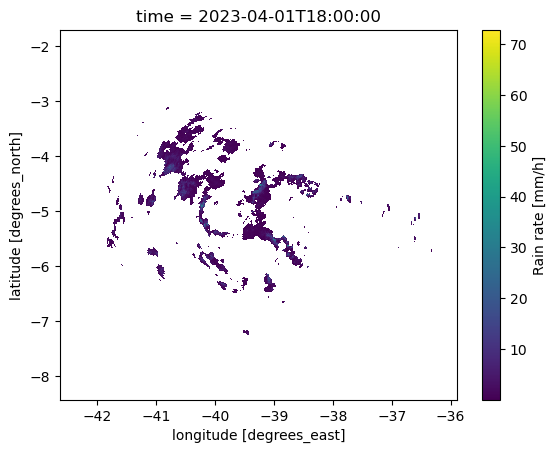

In [10]:
cart_grid.resample(time='30min').mean().sel(time='20230401T18H00M00S', method='nearest').rain_rate.plot()

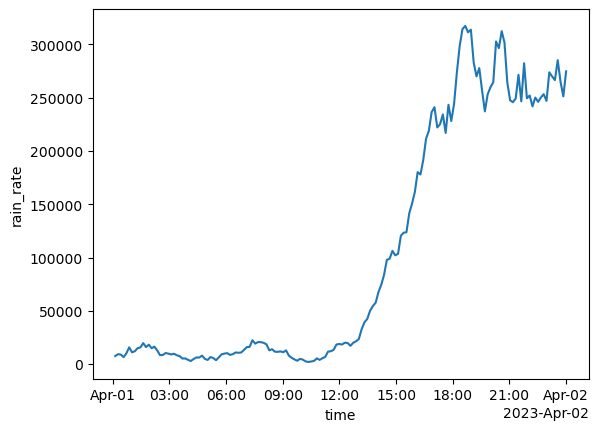

In [9]:
cart_grid.sum(dim=['lat', 'lon']).rain_rate.plot()

In [12]:
import xarray as xr
from pacha.L2_processing import radar as l2rad
import pandas as pd
import os

for date in dates:
    print(f"Processing date: {date}")
    try:
        if date == '2024-01-01':
            continue
        print(date)
        daily_xr = xr.open_dataset(df_paths_l1.loc[date].paths)
        cart_grid = l2rad.calc_rate_from_refl(daily_xr, offset=9)
        # change attributes and name and unit in xarray dataset
        cart_grid.attrs['title'] = f'FUNCEME radar L2 data for {date}'
        cart_grid.attrs['institution'] = 'FUNCEME'
        cart_grid.attrs['source'] = 'FUNCEME radar'
        cart_grid.attrs['history'] = f'Created on {pd.Timestamp.now()}'
        cart_grid.attrs['references'] = 'https://www.funceme.br/'
        cart_grid = cart_grid.rename({'dBZ': 'rain_rate'})
        cart_grid.rain_rate.attrs['long_name'] = 'Rain rate'
        cart_grid.rain_rate.attrs['units'] = 'mm/h'
        fname_netcdf = f'l2_radar_{date}.nc'
        dirpath = 'funceme_notebook_output/ds_l2_march_july/'
        fpath = os.path.join(dirpath, fname_netcdf)
        cart_grid.to_netcdf(fpath)
    except Exception as e:
        print(f"Error processing date {date}: {e}")

Processing date: 2023-04-01
2023-04-01
Processing date: 2023-04-02
2023-04-02
Processing date: 2023-04-03
2023-04-03
Processing date: 2023-04-04
2023-04-04
Processing date: 2023-04-05
2023-04-05
Processing date: 2023-04-06
2023-04-06
Processing date: 2023-04-07
2023-04-07
Processing date: 2023-04-08
2023-04-08
Processing date: 2023-04-09
2023-04-09
Processing date: 2023-04-10
2023-04-10
Processing date: 2023-04-11
2023-04-11
Processing date: 2023-04-12
2023-04-12
Processing date: 2023-04-13
2023-04-13
Processing date: 2023-04-14
2023-04-14
Processing date: 2023-04-15
2023-04-15
Processing date: 2023-04-16
2023-04-16
Processing date: 2023-04-17
2023-04-17
Processing date: 2023-04-18
2023-04-18
Processing date: 2023-04-19
2023-04-19
Processing date: 2023-04-20
2023-04-20
Processing date: 2023-04-21
2023-04-21
Processing date: 2023-04-22
2023-04-22
Processing date: 2023-04-23
2023-04-23
Processing date: 2023-04-24
2023-04-24
Processing date: 2023-04-25
2023-04-25
Processing date: 2023-04-

In [14]:
from pacha.utils import geospatial as gutils

In [16]:
gutils.get_bbox_from_xarray(cart_grid).__dict__

{'min_lat': array(-8.42523289),
 'min_lon': array(-42.63634109),
 'max_lat': array(-1.71533622),
 'max_lon': array(-35.89795832)}

In [17]:
"""Spatial averaging of regularly gridded lat/lon radar fields onto an aligned coarser grid."""

import numpy as np
import xarray as xr
from scipy.ndimage import convolve1d


def _infer_grid_step(values, name):
    """Return native step in degrees after validating a regular, monotonic 1-D axis."""
    values = np.asarray(values, dtype=np.float64)
    if values.ndim != 1 or values.size < 2 or not np.all(np.isfinite(values)):
        raise ValueError(f"'{name}' must be a 1-D numeric coordinate with >=2 finite values")
    differences = np.diff(values)
    if not (np.all(differences > 0) or np.all(differences < 0)):
        raise ValueError(f"'{name}' must be strictly monotonic")
    step = float(np.median(np.abs(differences)))
    if not np.allclose(np.abs(differences), step, rtol=0.01, atol=1e-10):
        raise ValueError(f"'{name}' must be regularly spaced (within 1%)")
    return step


def _target_centers(values, step):
    """Global 0.5*step-offset centers with entire output footprint within source coords."""
    lo, hi = float(np.min(values)), float(np.max(values))
    # Centers are (k + 0.5)*step and their edges are k*step, (k+1)*step.
    # Require those two edges to stay within [lo, hi].
    eps = 1e-10
    k_first = int(np.ceil(lo / step - eps))
    k_last = int(np.floor(hi / step - 1 + eps))
    if k_last < k_first:
        raise ValueError(f"Source domain [{lo}, {hi}] cannot fit a full {step:g}° output cell")
    return (np.arange(k_first, k_last + 1, dtype=np.int64) + 0.5) * step


def _box_weights(width_in_source_pixels):
    """Normalized symmetric weights accounting for partially covered edge pixels."""
    half_width = width_in_source_pixels / 2.0
    radius = int(np.ceil(half_width + 0.5))
    offsets = np.arange(-radius, radius + 1, dtype=np.float64)
    overlap = np.maximum(
        0.0,
        np.minimum(offsets + 0.5, half_width)
        - np.maximum(offsets - 0.5, -half_width),
    )
    overlap = overlap[overlap > 1e-12]
    return overlap / overlap.sum()


def _mean_filter_2d(arr, w_lat, w_lon, min_valid_fraction):
    """Separable NaN-aware box convolution for one (lat, lon) frame."""
    valid = np.isfinite(arr)
    cleaned = np.where(valid, arr, 0).astype(np.float64, copy=False)
    weights = valid.astype(np.float64)

    for axis, kernel in ((0, w_lat), (1, w_lon)):
        cleaned = convolve1d(cleaned, kernel, axis=axis, mode="constant", cval=0.0)
        weights = convolve1d(weights, kernel, axis=axis, mode="constant", cval=0.0)

    result = np.full(cleaned.shape, np.nan, dtype=np.float64)
    np.divide(
        cleaned,
        weights,
        out=result,
        where=(weights > 0) & (weights >= min_valid_fraction - 1e-10),
    )
    return result


def spatial_average_resample(data, resolution=0.1, *, min_valid_fraction=0.8,
                             method="linear"):
    """Spatially average a regular lat/lon DataArray or Dataset on a new grid.

    Parameters
    ----------
    data : xr.DataArray or xr.Dataset
        Fields with 1-D 'lat' and 'lon' coordinates. Extra dims, e.g. time,
        are preserved. Dataset variables with both lat/lon are averaged;
        variables without either dimension are copied unchanged.
    resolution : float or (lat_step, lon_step)
        Target grid spacing in degrees, e.g. 0.1 or (0.1, 0.1).
        Output centers are aligned to (..., -0.05, 0.05, 0.15, ...)
        for resolution=0.1, excluding cells whose *edges* lie outside
        the primary coordinates.
    min_valid_fraction : float, default 0.8
        Minimum fraction of the convolution footprint having finite data.
        The mean is calculated using valid cells only; set 1.0 to demand
        complete coverage.
    method : {'linear', 'nearest'}, default 'linear'
        Sampling of the smoothed radar field at output cell centers.
        'nearest' more closely reproduces the original notebook method;
        'linear' better handles offset between source and target centers.

    Returns
    -------
    xr.DataArray or xr.Dataset
        Spatially averaged data on the newly built regular output grid.
        Spatial coordinates are ascending; no disk output is written.

    Notes
    -----
    This approximates cell averages using a symmetric box convolution before
    resampling; it is not exact conservative area-overlap remapping.
    Coordinates must be rectilinear longitude/latitude in degrees.
    """
    if not isinstance(data, (xr.DataArray, xr.Dataset)):
        raise TypeError("data must be an xarray DataArray or Dataset")
    if 'lat' not in data.dims or 'lon' not in data.dims:
        raise ValueError("data must have 'lat' and 'lon' dimensions")
    for coord in ('lat', 'lon'):
        if coord not in data.coords or data[coord].dims != (coord,):
            raise ValueError(f"'{coord}' must be a 1-D dimension coordinate")
    if np.isscalar(resolution):
        target_lat_step = target_lon_step = float(resolution)
    else:
        if len(resolution) != 2:
            raise ValueError("resolution must be one number or (lat_step, lon_step)")
        target_lat_step, target_lon_step = map(float, resolution)
    if not all(np.isfinite([target_lat_step, target_lon_step])) or min(target_lat_step, target_lon_step) <= 0:
        raise ValueError("resolution must be strictly positive and finite")
    if not 0 < min_valid_fraction <= 1:
        raise ValueError("min_valid_fraction must be in (0, 1]")
    if method not in ('linear', 'nearest'):
        raise ValueError("method must be 'linear' or 'nearest'")

    src_lat_step = _infer_grid_step(data.lat.values, 'lat')
    src_lon_step = _infer_grid_step(data.lon.values, 'lon')
    if target_lat_step < src_lat_step * (1 - 1e-8) or target_lon_step < src_lon_step * (1 - 1e-8):
        raise ValueError("Output resolution must be coarser than or equal to both input steps")

    new_lat = _target_centers(data.lat.values, target_lat_step)
    new_lon = _target_centers(data.lon.values, target_lon_step)
    w_lat = _box_weights(target_lat_step / src_lat_step)
    w_lon = _box_weights(target_lon_step / src_lon_step)

    data = data.sortby('lat').sortby('lon')

    def apply_to_da(da):
        if not {'lat', 'lon'}.issubset(da.dims):
            if {'lat', 'lon'} & set(da.dims):
                raise ValueError(f"Variable {da.name!r} has only one spatial dimension")
            return da.copy()
        if not np.issubdtype(da.dtype, np.number):
            raise TypeError(f"Variable {da.name!r} must contain numerical data")
        smoothed = xr.apply_ufunc(
            _mean_filter_2d,
            da,
            input_core_dims=[['lat', 'lon']],
            output_core_dims=[['lat', 'lon']],
            kwargs={'w_lat': w_lat, 'w_lon': w_lon,
                    'min_valid_fraction': min_valid_fraction},
            vectorize=True,
            dask='parallelized',
            dask_gufunc_kwargs={'allow_rechunk': True},
            output_dtypes=[np.float64],
            keep_attrs=True,
        )
        return smoothed.interp(lat=new_lat, lon=new_lon, method=method)

    if isinstance(data, xr.DataArray):
        result = apply_to_da(data)
    else:
        result = xr.Dataset(
            {name: apply_to_da(da) for name, da in data.data_vars.items()},
            attrs=data.attrs.copy(),
        )

    result.attrs.update({
        'spatial_resampling': 'NaN-aware box convolution then ' + method + ' sampling',
        'source_lat_step_degrees': src_lat_step,
        'source_lon_step_degrees': src_lon_step,
        'target_lat_step_degrees': target_lat_step,
        'target_lon_step_degrees': target_lon_step,
        'spatial_kernel_size': f'{len(w_lat)}x{len(w_lon)}',
    })
    return result

In [ ]:
spatial_average_resample(cart_grid)

In [89]:
for date in dates:
    print(f"Processing date: {date}")
    try:
        if date == '2024-01-01':
            continue
        print(date)
        daily_xr = open_daily_funceme(paths_df, date)
        cart_grid = to_lonlat(daily_xr)
        fname_netcdf = f'l1_radar_{date}.nc'
        dirpath = 'funceme_notebook_output/ds_out_march_july/'
        fpath = os.path.join(dirpath, fname_netcdf)
        cart_grid.to_netcdf(fpath)
    except Exception as e:
        print(f"Error processing date {date}: {e}")

Processing date: 2023-04-01
2023-04-01
Processing date: 2023-04-02
2023-04-02
Processing date: 2023-04-03
2023-04-03
Processing date: 2023-04-04
2023-04-04
Processing date: 2023-04-05
2023-04-05
Processing date: 2023-04-06
2023-04-06
Processing date: 2023-04-07
2023-04-07
Processing date: 2023-04-08
2023-04-08
Processing date: 2023-04-09
2023-04-09
Processing date: 2023-04-10
2023-04-10
Processing date: 2023-04-11
2023-04-11
Processing date: 2023-04-12
2023-04-12
Processing date: 2023-04-13
2023-04-13
Processing date: 2023-04-14
2023-04-14
Processing date: 2023-04-15
2023-04-15
Processing date: 2023-04-16
2023-04-16
Processing date: 2023-04-17
2023-04-17
Processing date: 2023-04-18
2023-04-18
Processing date: 2023-04-19
2023-04-19
Processing date: 2023-04-20
2023-04-20
Processing date: 2023-04-21
2023-04-21
Processing date: 2023-04-22
2023-04-22
Processing date: 2023-04-23
2023-04-23
Processing date: 2023-04-24
2023-04-24
Processing date: 2023-04-25
2023-04-25
Processing date: 2023-04-

In [8]:
retained_dates = dates[1:]

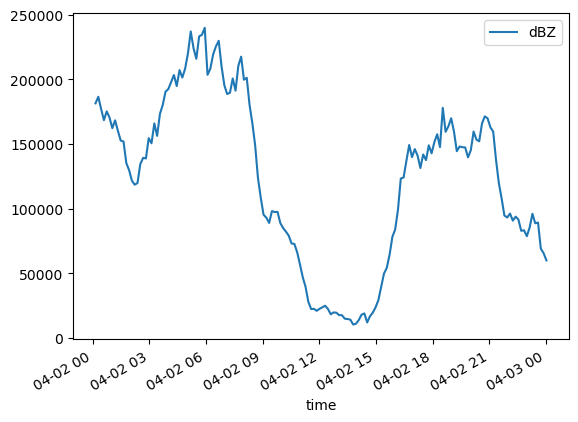

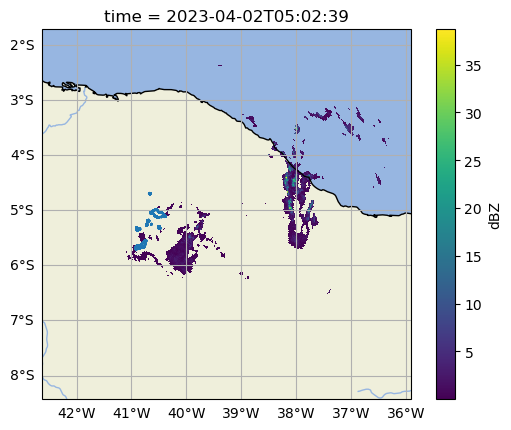

In [10]:
import os 
path_shape = '/media/admingosset/T7Shield/data/reference/ceara/basin_crateus_final_shp/'
fpaths = futils.get_fpaths_from_dir(path_shape)
shps = [i for i in fpaths if i.endswith('.shp')]

import geopandas as gpd
dfs_shps = [gpd.read_file(i) for i in shps]

fpath = '/home/admingosset/WORK/projects/CEARA_FUNCEME/funceme_notebook_output/dss_out/rainfall_test_2023_04_02.nc'

ds = xr.open_dataset(fpath)

ds.sum(dim=['lat', 'lon']).to_dataframe().plot()
plt.show()
gvis.plot_simple_map()
ax = plt.gca()
ds.sel(time='2023-04-02T050000', method='nearest').dBZ.plot(ax=ax)
for df in dfs_shps:
    df.boundary.plot(ax=ax)

In [ ]:
de_resampled = ds_conv.sel()

<xarray.Dataset> Size: 4GB
Dimensions:  (time: 290, lat: 1856, lon: 1869)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2024-03-31T00:05:18 ... 2024-03-31T23:...
  * lat      (lat) float64 15kB -8.425 -8.422 -8.418 ... -1.723 -1.719 -1.715
  * lon      (lon) float64 15kB -42.64 -42.63 -42.63 ... -35.91 -35.9 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 4GB dask.array<chunksize=(1, 1856, 1869), meta=np.ndarray>
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  400.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2024-03-31 00:02:52
    source_first_scan_t_f:   2024-03-31 00:07:44

<Axes: >

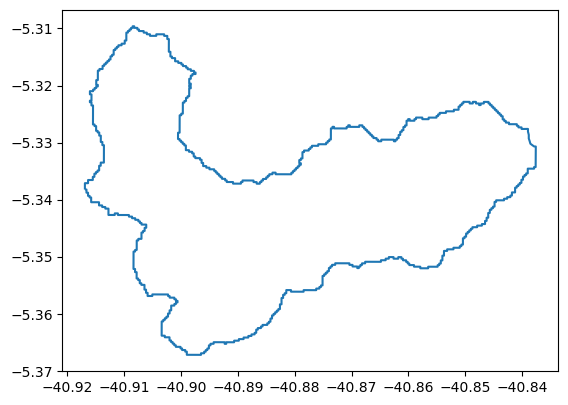

In [11]:
dfs_shps[0].boundary.plot()

<Axes: xlabel='lat,lon'>

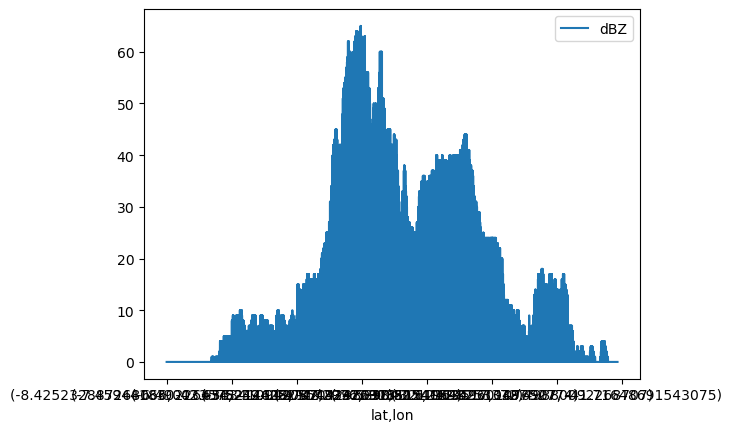

In [12]:
ds.count(dim='time').to_dataframe().plot()

In [38]:
daily_dss.keys()

NameError: name 'daily_dss' is not defined

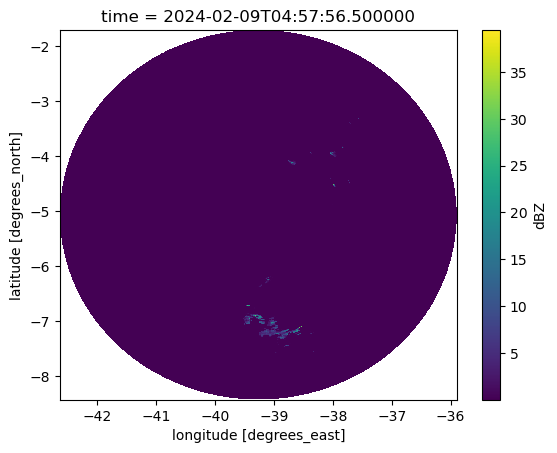

In [157]:
daily_dss['2024-02-09'].sel(time='2024-02-09T050000', method='nearest').dBZ.plot()

In [14]:
gauges = iutils.Gauges('funceme_notebook_output/station_data_rain_tot.csv', 'funceme_notebook_output/station_metadata.csv')
gauges.data.columns = gauges.metadata.index
gauges.metadata.rename(columns={'station': 'name'}, inplace=True)
lon0, lat0 = gutils.calc_ds_center(ds)
gauges.calc_distance_to_point((lat0, lon0))

/tmp/ipykernel_9319/3164890556.py:18: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(ngau, 1, sharex=True, figsize=(6, 2*ngau))


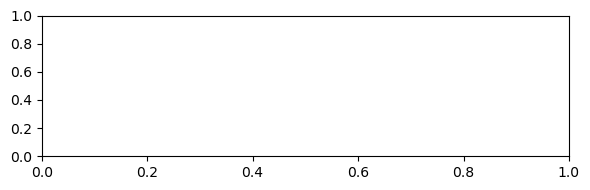

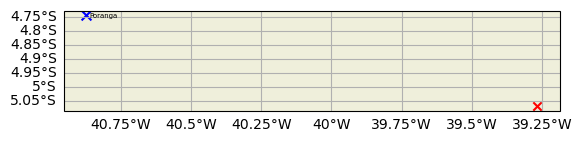

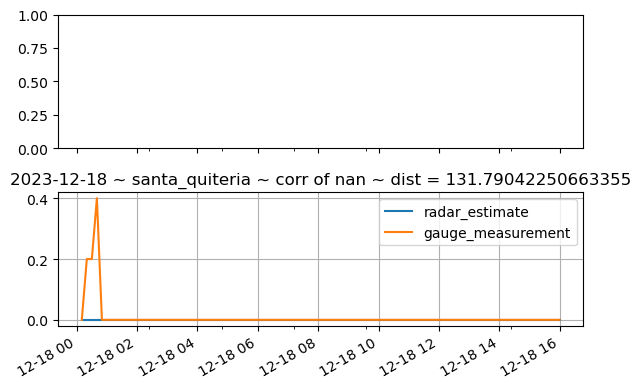

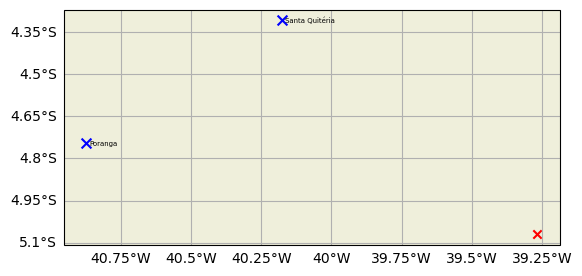

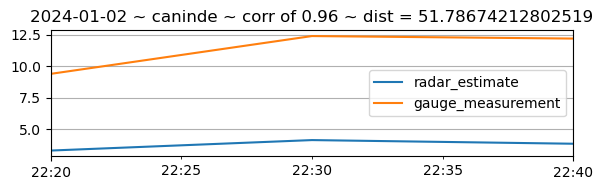

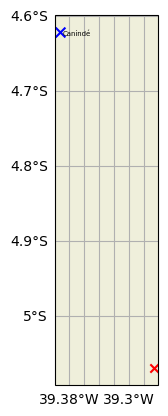

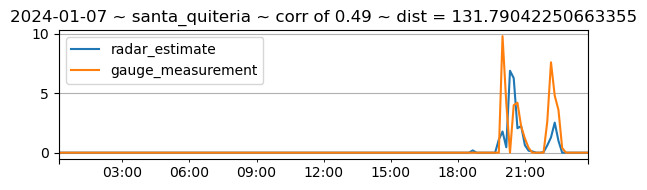

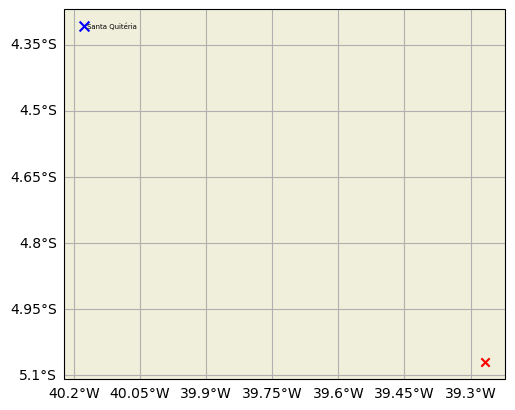

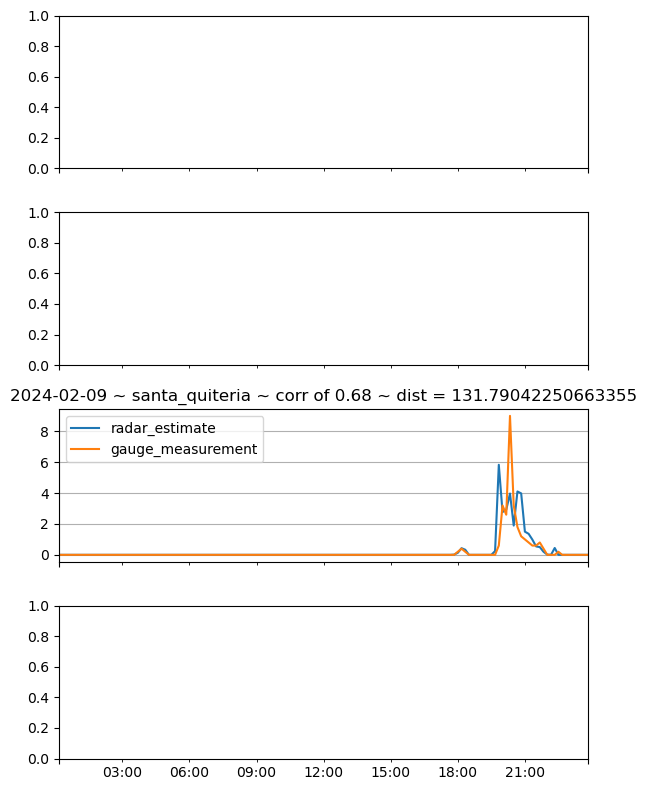

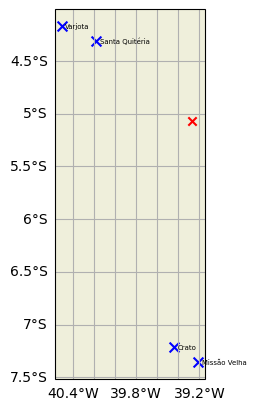

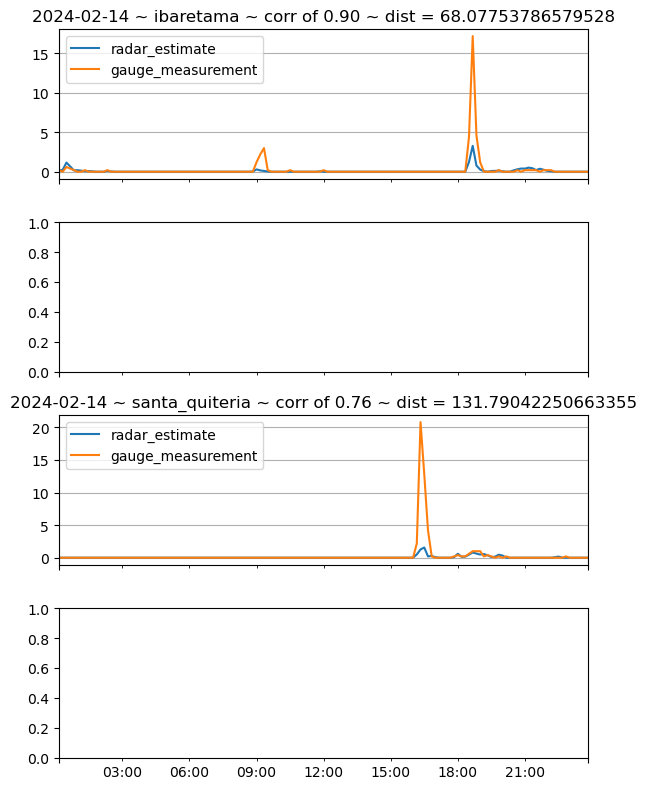

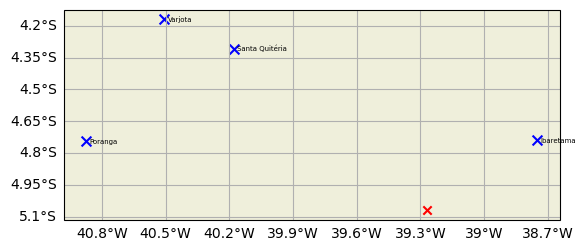

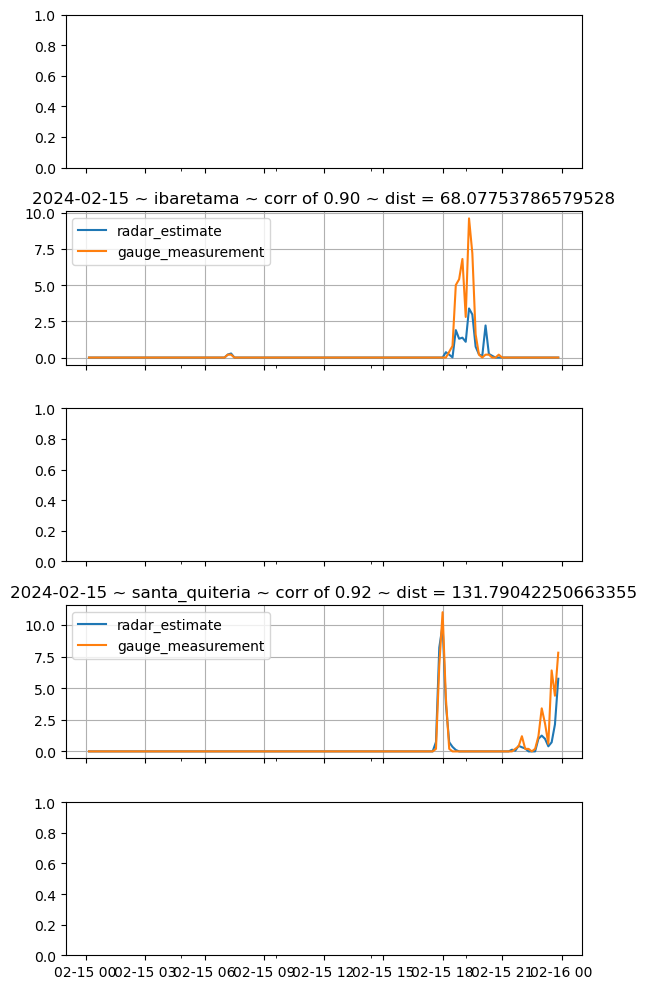

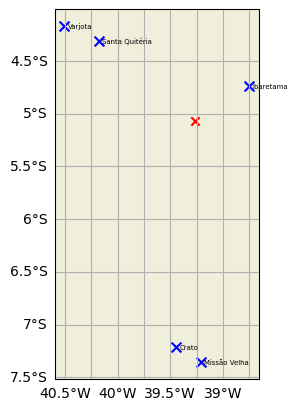

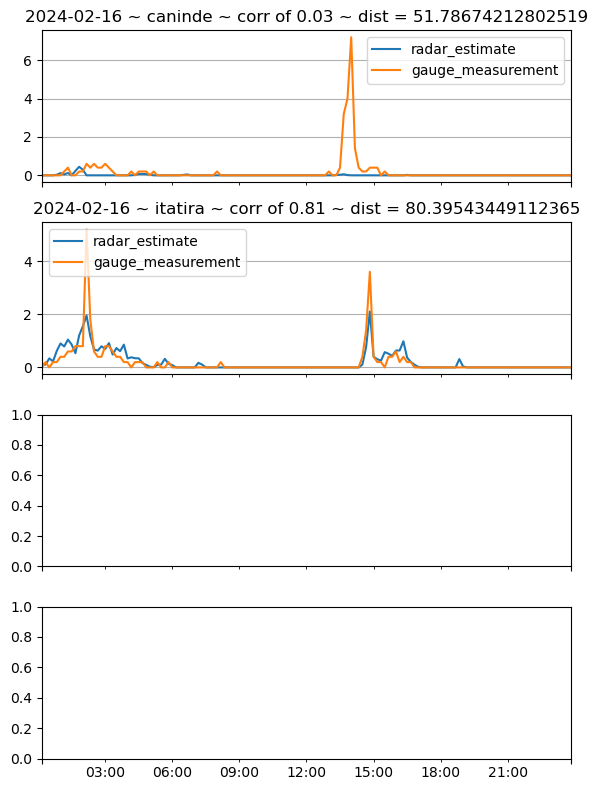

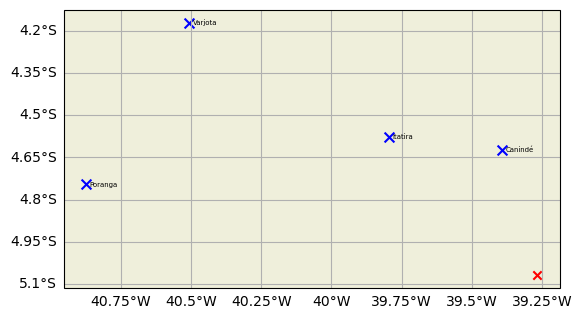

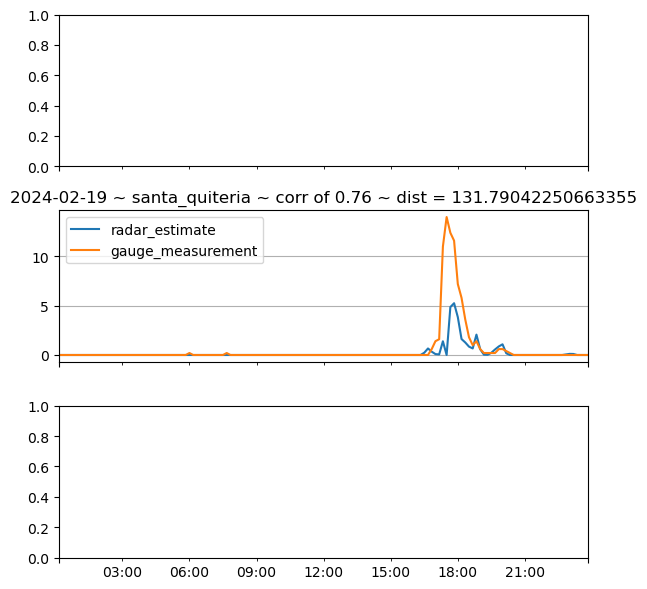

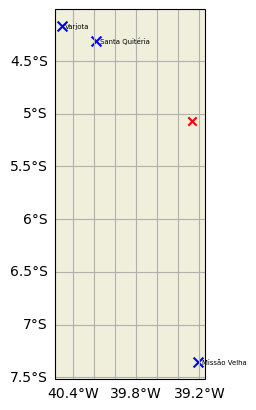

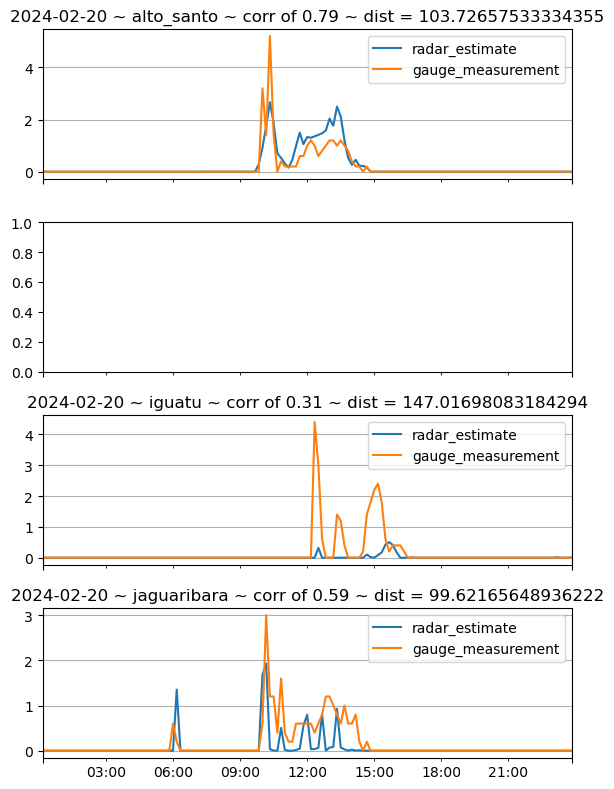

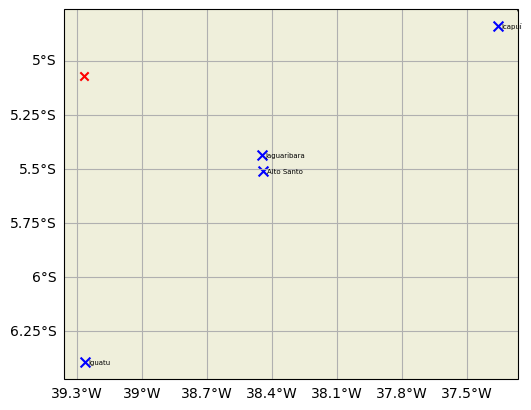

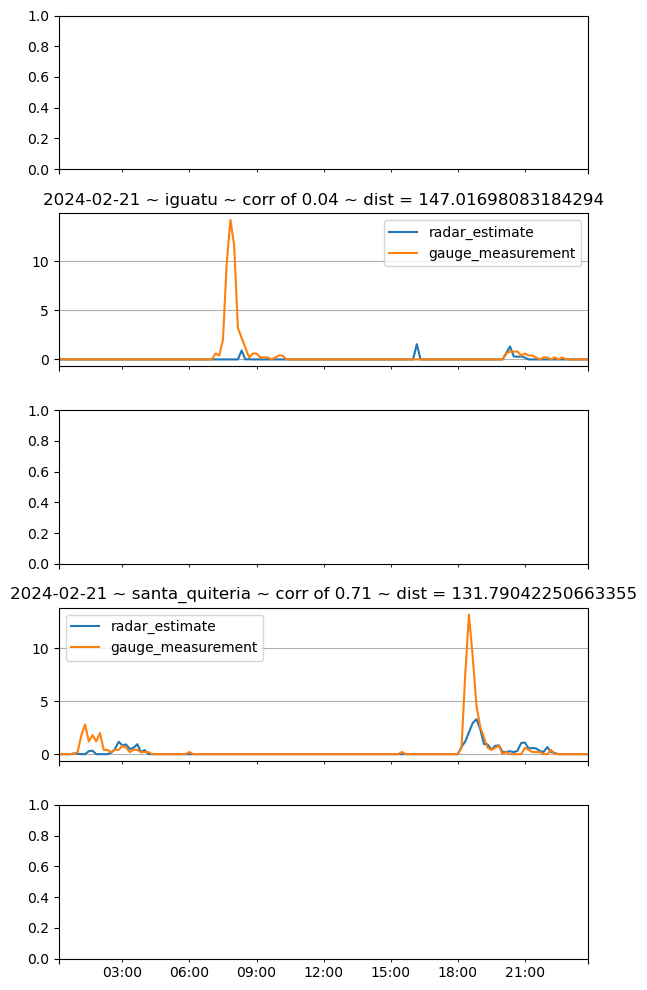

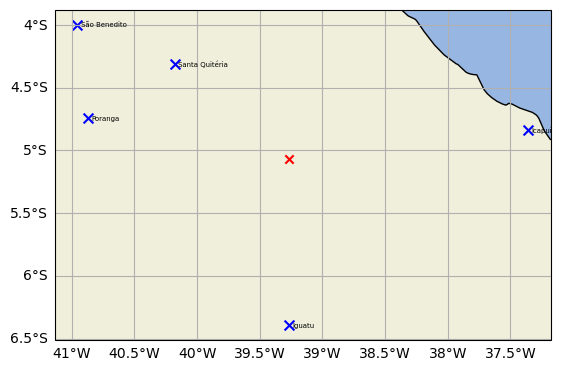

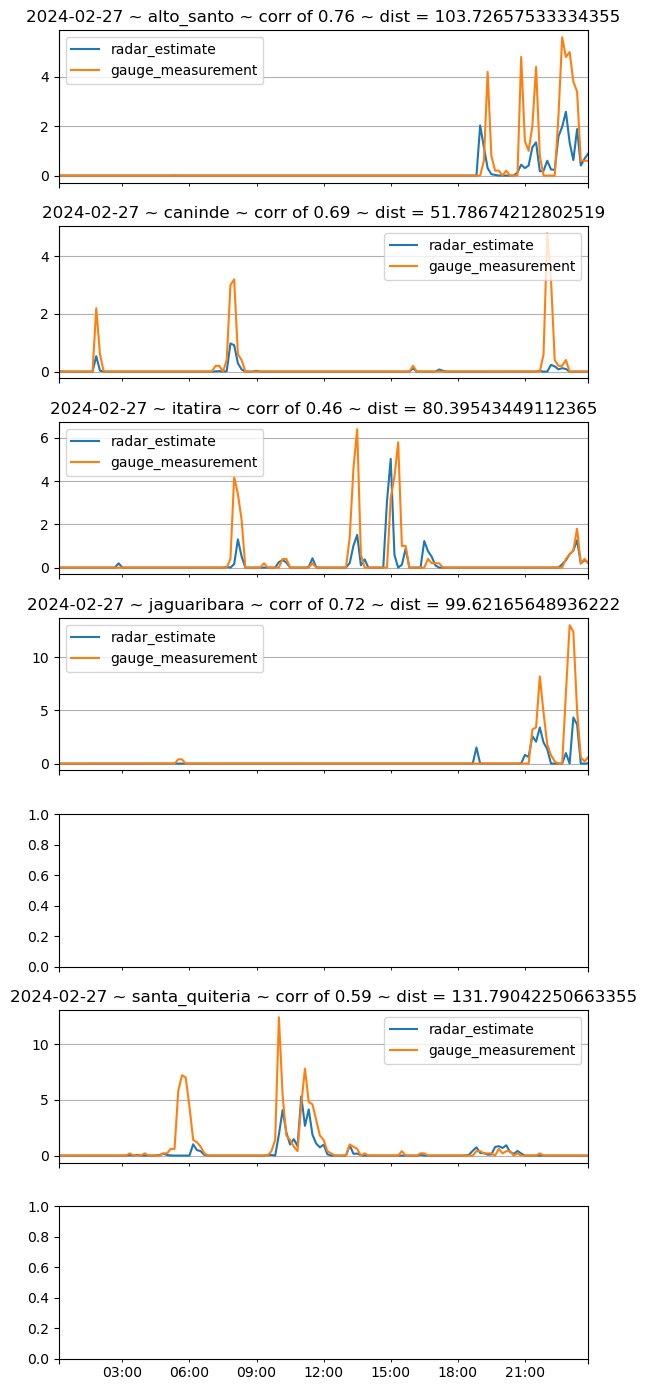

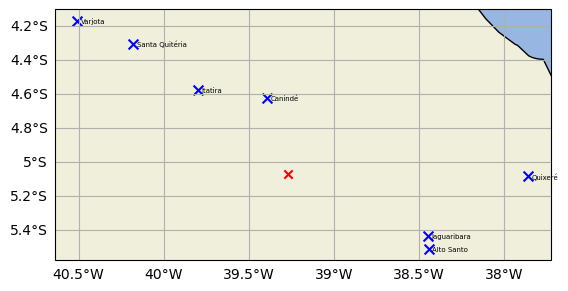

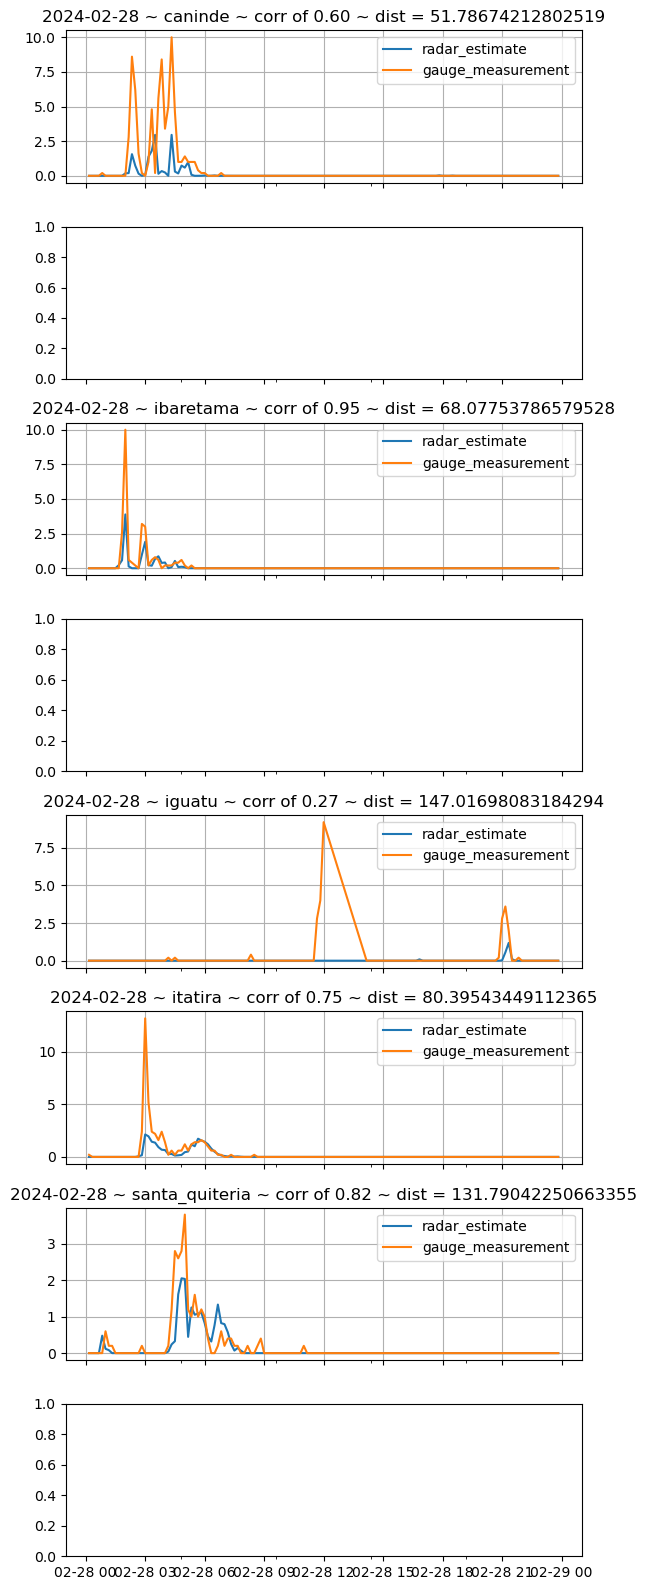

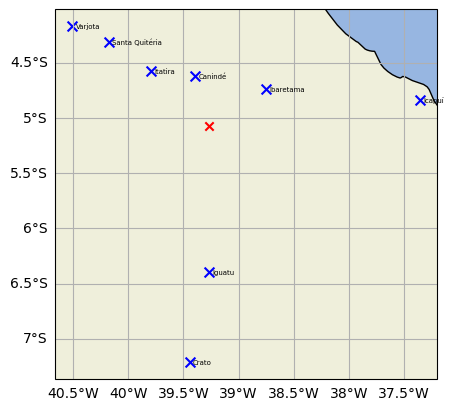

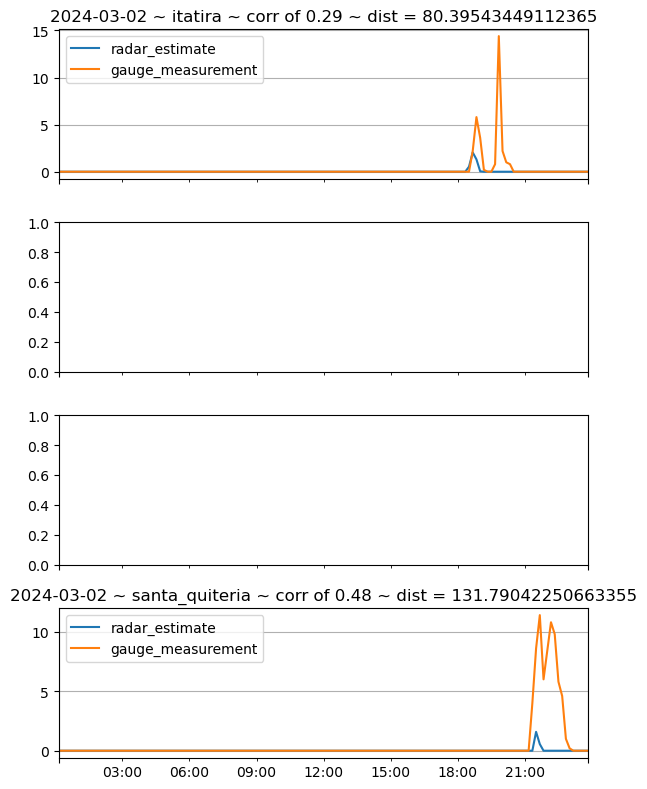

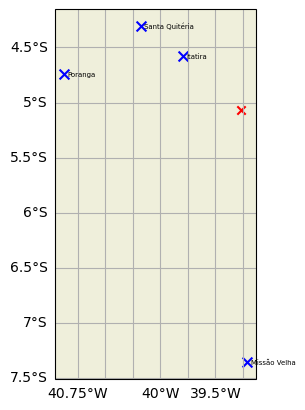

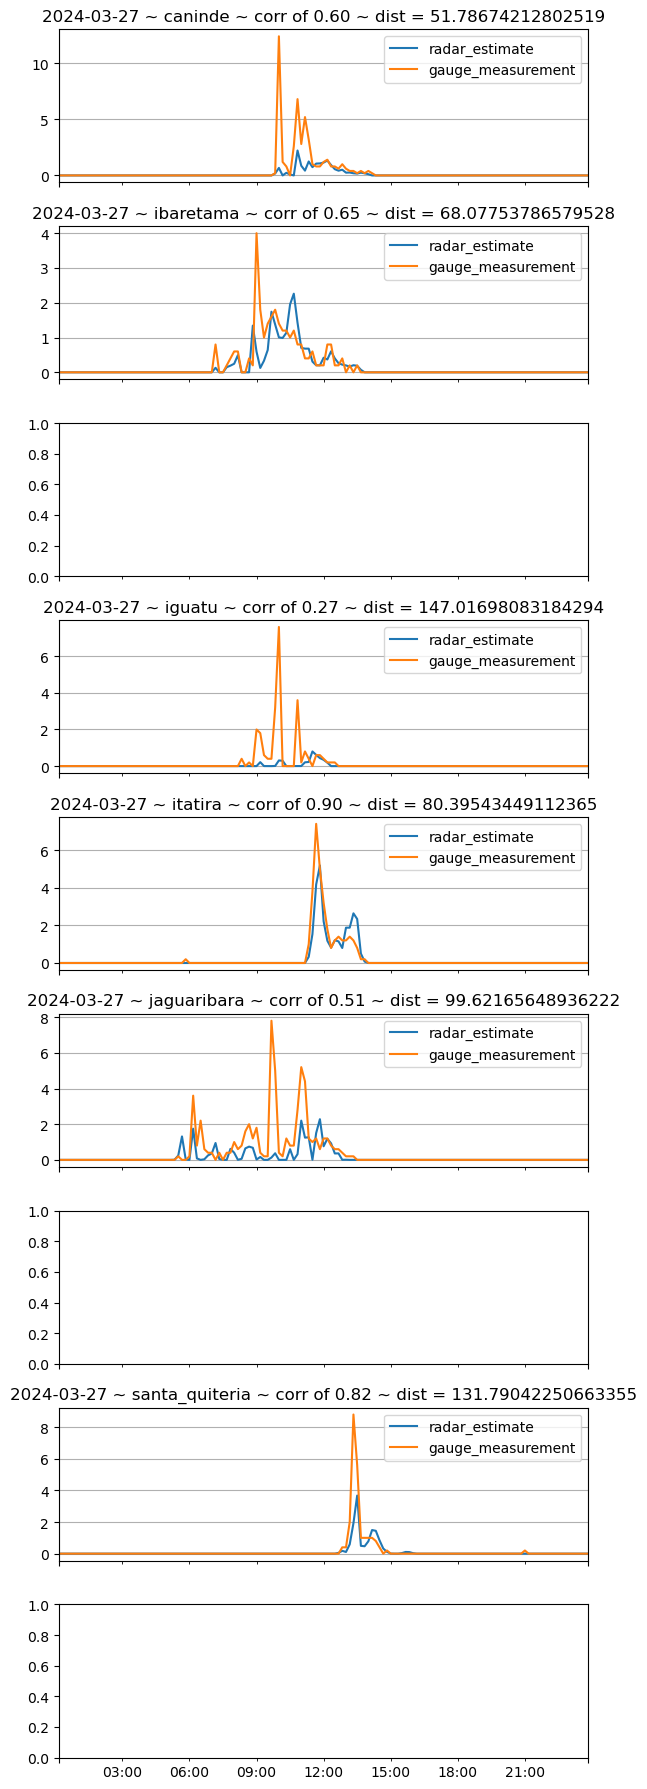

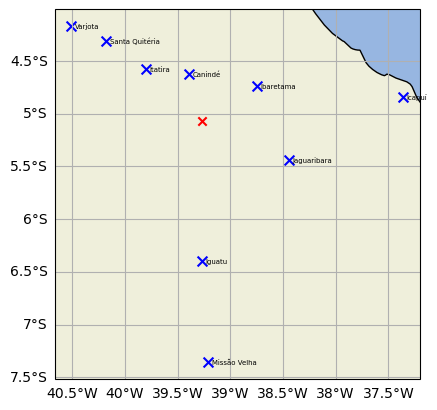

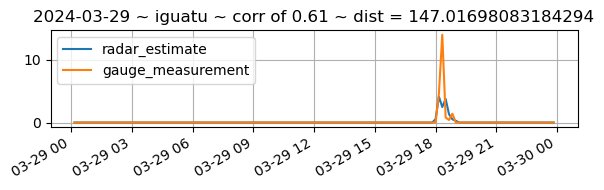

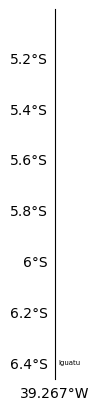

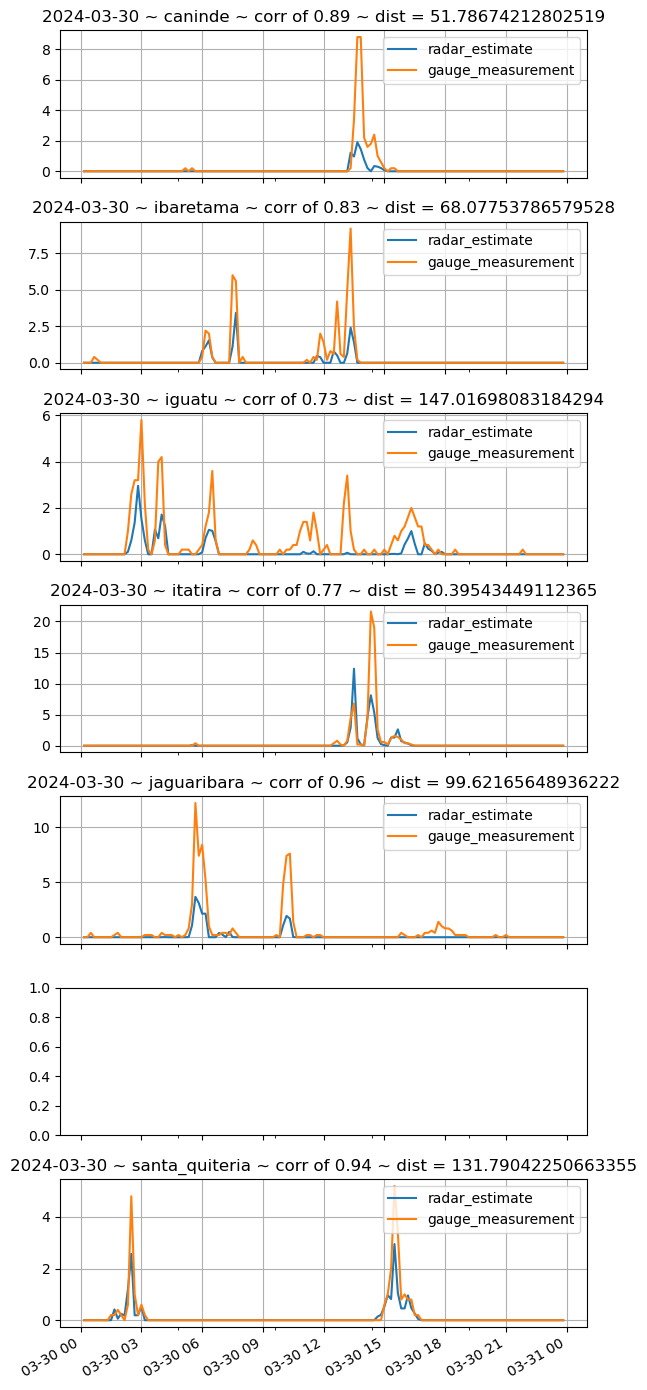

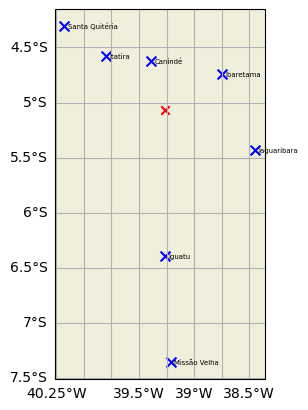

In [165]:
#lon0, lat0 = gutils.calc_ds_center(daily_xr)
dfs = []
for date in sel_dates:
    if date == '2024-01-01':
        continue
    ds = daily_dss[date]
    ds.fillna(0)
    data_gauges_date = gauges.data.loc[date]
    daily_sum = (data_gauges_date.sum())
    daily_mask = daily_sum > 20
    gauges_date = gauges.metadata.loc[daily_mask].index
    daily_data = data_gauges_date.loc[:, gauges_date]
    gauges_date = gauges_date.tolist()
    gauges_date = [i for i in gauges_date if i != 'baturite']
    ngau = len(gauges_date)
    if ngau < 1:
        continue
    fig, axes = plt.subplots(ngau, 1, sharex=True, figsize=(6, 2*ngau))
    if not isinstance(axes, np.ndarray):
        axes = [axes]
    for gauge, ax in zip(gauges_date, axes):
        if gauges.metadata.loc[gauge, "distance_to_point"] > 150:
            continue
        lon, lat = gauges.get_coords_station(gauge)
        df_rad_at_gauge = gutils.ds_to_df_at_point(ds, (lon, lat))
        daily_gauge = daily_data.loc[:, gauge]
        rad_at_ten_min = df_rad_at_gauge.resample('10min', label="right", closed="right",).mean()
        rad_10_mean_acc = rad_at_ten_min * (10 / 60)
        gau_rad = pd.concat([rad_10_mean_acc, daily_gauge], axis=1).dropna()
        gau_rad = gau_rad.rename(columns={'dBZ': "radar_estimate", gauge: 'gauge_measurement'})
        corr = gau_rad.corr().iloc[0,1]
        if gau_rad.empty:
            continue
        gau_rad.plot(ax=ax, title=f'{date} ~ {gauge} ~ corr of {corr:0.2f} ~ dist = {gauges.metadata.loc[gauge, "distance_to_point"]}')
        ax.grid()
        dfs.append(gau_rad)
    fig.tight_layout()
    fig.savefig(f'funceme_notebook_output/figs/{date}_graphs.png')
    fig = plt.figure()
    gvis.plot_simple_map()
    gvis.plot_gauge_network(gauges.metadata.loc[gauges_date], display_names=True)
    ax = plt.gca()
    ax.scatter(lon0, lat0, marker='x', c='r')    
    fig.savefig(f'funceme_notebook_output/figs/{date}_map.png')

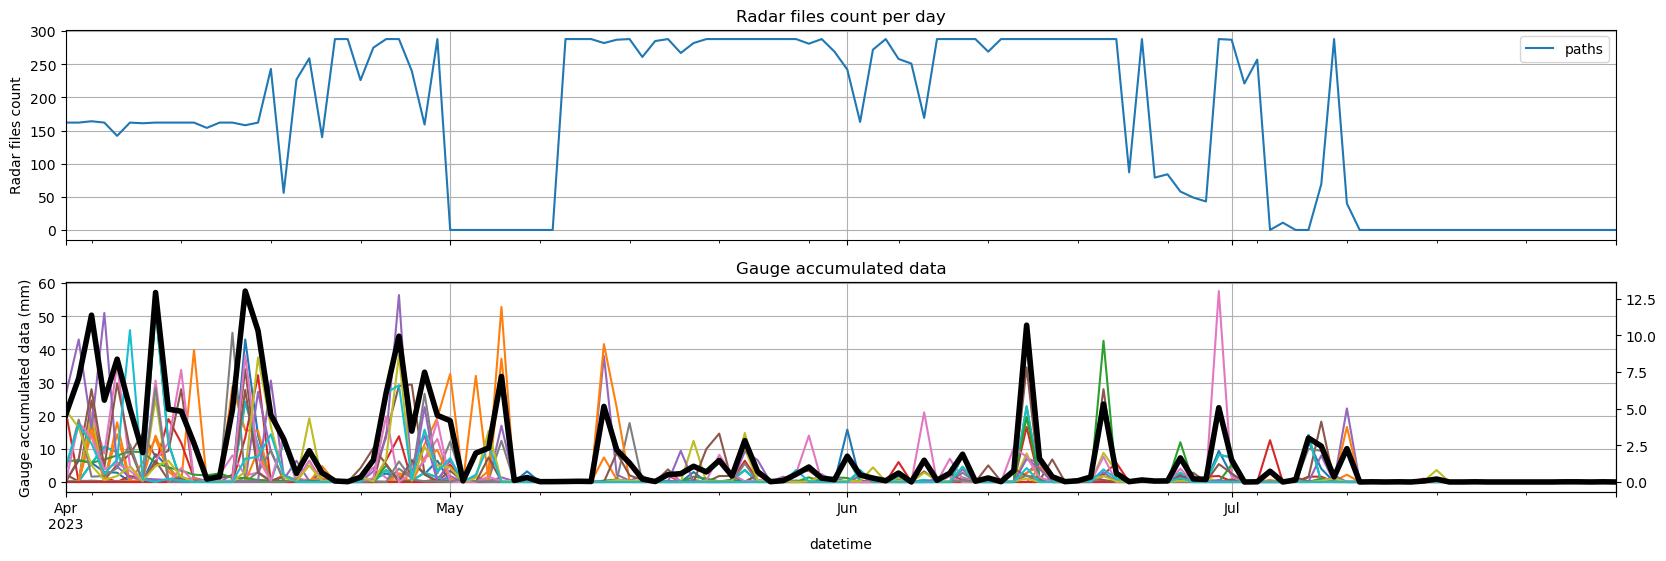

In [15]:
fig, axes = plt.subplots(2,1, sharex=True, figsize=(20, 6))
paths_count = paths_df.groupby(pd.Grouper(freq='1D')).count().loc['2023-04':'2023-07']
paths_count.plot(ax=axes[0])
gauges.data.groupby(pd.Grouper(freq='1D')).sum().loc['2023-04':'2023-07'].plot(legend=False, ax=axes[1])
ax3 = axes[1].twinx()
mean_acc_gauges = gauges.data.groupby(pd.Grouper(freq='1D')).sum(min_count=100).mean(axis=1).loc['2023-04':'2023-07']
mean_acc_gauges.plot(linewidth=4, legend=False, ax=ax3, color='k')
titles = ['Radar files count per day', 'Gauge accumulated data']
# add titles to axes
for ax, title in zip(axes, titles):
    ax.set_title(title)
# add labels on axis
axes[0].set_ylabel('Radar files count')
axes[1].set_ylabel('Gauge accumulated data (mm)')
axes[0].grid()
axes[1].grid()

In [16]:
dates_over_150 = paths_count.loc[(paths_count>150).to_numpy()].index
dates_over_150 = set([i for i in dates_over_150])
dates_acc = mean_acc_gauges.loc[mean_acc_gauges>5].index
dates_acc = set([i for i in dates_acc])

dates_gauges = [str(i.date()) for i in mean_acc_gauges.loc[(mean_acc_gauges > 5)].index]
radar_gau_2023 = [i for i in dates_gauges if i in [str(j.date()) for j in list(dates_over_150)]]

In [17]:
stations_for_calibration

NameError: name 'stations_for_calibration' is not defined

In [108]:
dfs_30min = []
for date in radar_gau_2023:
    df_gauges = gauges.data.loc[date, stations_for_calibration]
    stations_over_5 = [i for i in df_gauges.columns[df_gauges.sum(min_count=140) > 5]]
    if len(stations_over_5) < 1:
        print(f"No stations with sufficient data for date {date}.")
        continue
    display(stations_over_5)
    ds_rad = xr.open_dataset(df_paths_l1.loc[date].paths)
    ds_rain = l2rad.calc_rate_from_refl(ds_rad, offset=15).fillna(0)
    dfs_by_cols = []
    for row in gauges.metadata.loc[stations_over_5].iterrows():
        lon, lat = row[1].lon, row[1].lat
        df_rad_at_gauge = gutils.ds_to_df_at_point(ds_rain, (lon, lat))
        # rename column to gauge name
        df_rad_at_gauge.rename(columns={'dBZ': f'{row[0]}_radar_estimate'}, inplace=True)
        dfs_by_cols.append(df_rad_at_gauge)
    df_gauges_from_rad = pd.concat(dfs_by_cols, axis=1)
    rad_estimate_30min_acc = (df_gauges_from_rad.resample('30min', label="right", closed="right").mean())*0.5
    gau_measurement_acc_30min = gauges.data.loc[date, stations_over_5].resample('30min', label="right", closed="right").sum()
    rad_v_gauges = pd.concat([rad_estimate_30min_acc, gau_measurement_acc_30min], axis=1)
    dfs_30min.append(rad_v_gauges)

['santa_quiteria', 'alto_santo']

['ibaretama', 'itatira', 'alto_santo']

No stations with sufficient data for date 2023-04-04.


['ibaretama']

['ibaretama', 'itatira', 'alto_santo']

...

['ibaretama']

No stations with sufficient data for date 2023-04-29.
No stations with sufficient data for date 2023-05-13.


['ibaretama', 'itatira', 'alto_santo']

['ibaretama', 'itatira']

['alto_santo']

In [109]:
import pandas as pd

pairs = []

for df in dfs_30min:
    for col in df.columns:
        if col.endswith("_radar_estimate"):
            station = col.removesuffix("_radar_estimate")

            if station in df.columns:
                pair = df[[col, station]].rename(columns={
                    col: "radar_estimate",
                    station: "gauge_measurement"
                })
                pairs.append(pair)

df_pairs = pd.concat(pairs).dropna().sort_index()

In [110]:
gauge_over_02 = df_pairs.loc[df_pairs.loc[:, "gauge_measurement"]>0.2]
gauge_rad_over_02 = gauge_over_02.loc[gauge_over_02.loc[:, "radar_estimate"]>0.2]

np.float64(0.2819544610135269)

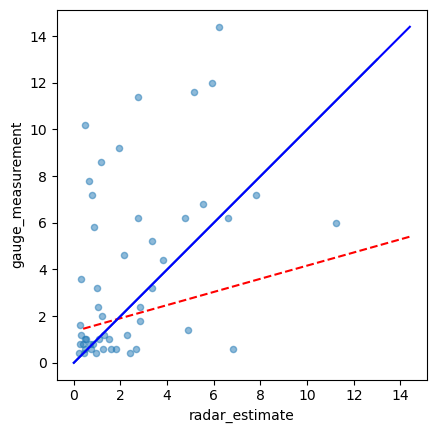

In [116]:
from pacha.visualisation import statistical as svis
gauge_rad_over_02.plot.scatter(x='radar_estimate', y='gauge_measurement', alpha=0.5)
ax = plt.gca()
ax.set_aspect('equal')
ax.plot(np.arange(14))
svis.plot_fit(gauge_rad_over_02.gauge_measurement, gauge_rad_over_02.radar_estimate)

In [ ]:
for

(43, 2)

In [97]:
gauge_rad_over_02.corr()

,radar_estimate,gauge_measurement
radar_estimate,1.000000,0.309475
gauge_measurement,0.309475,1.000000


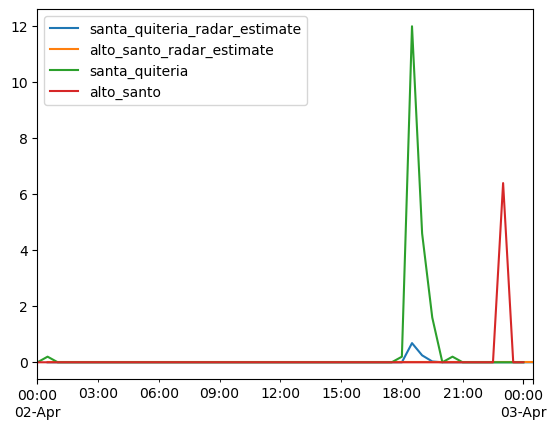

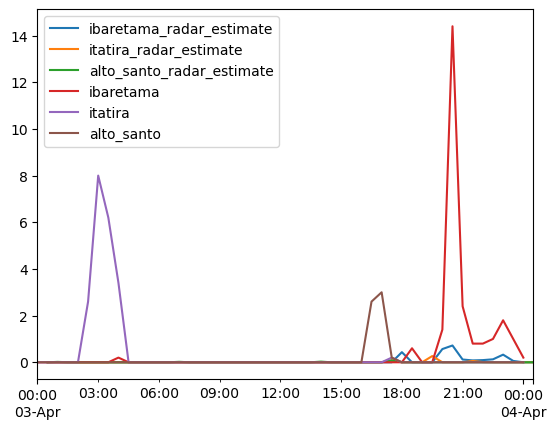

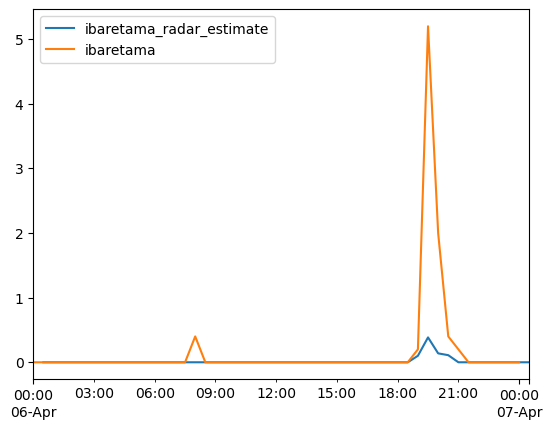

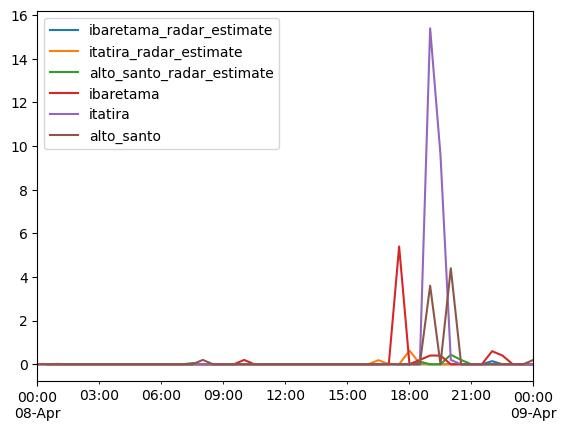

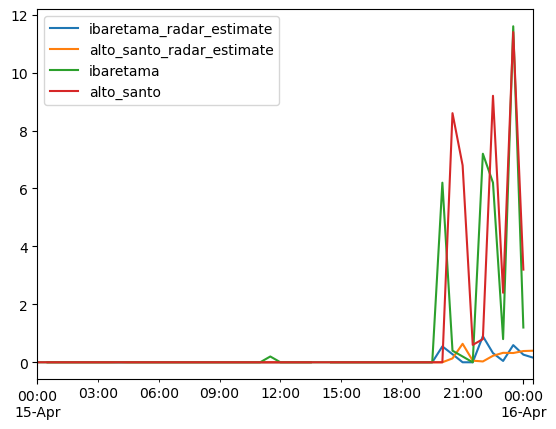

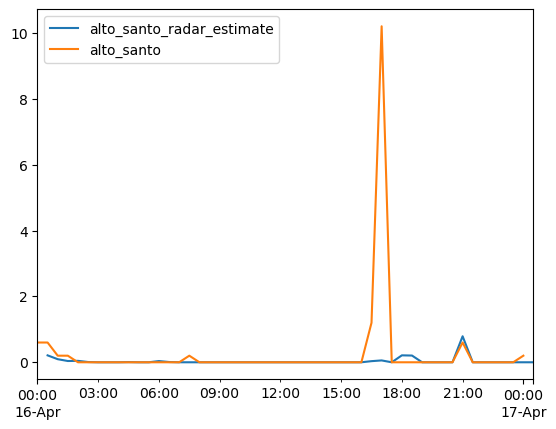

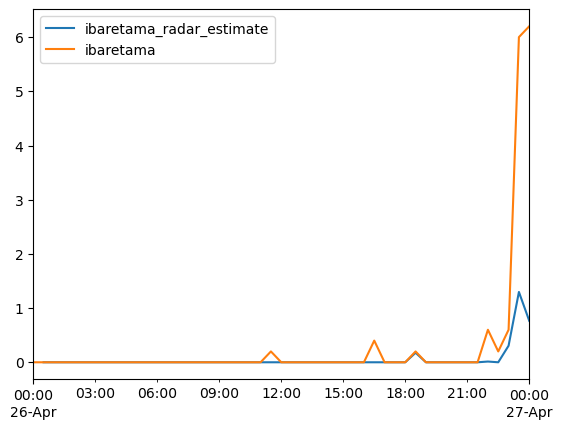

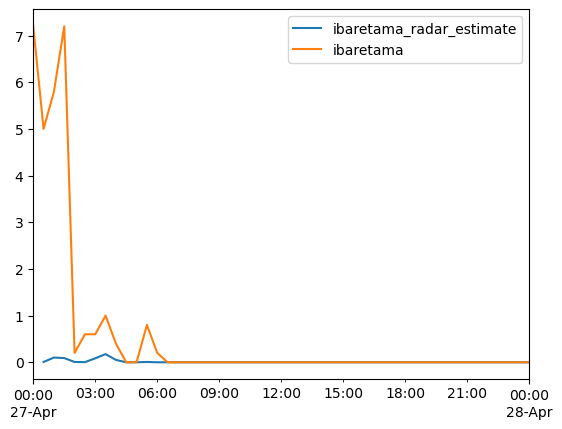

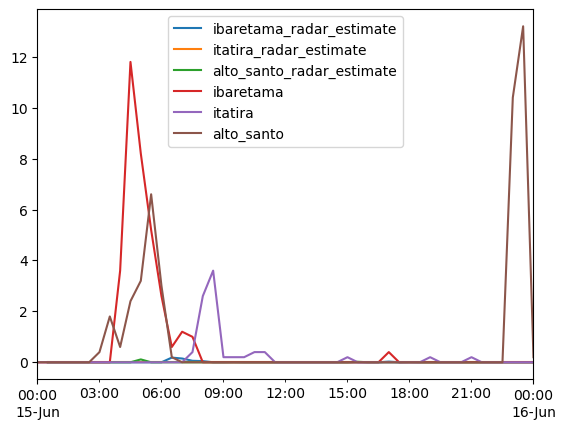

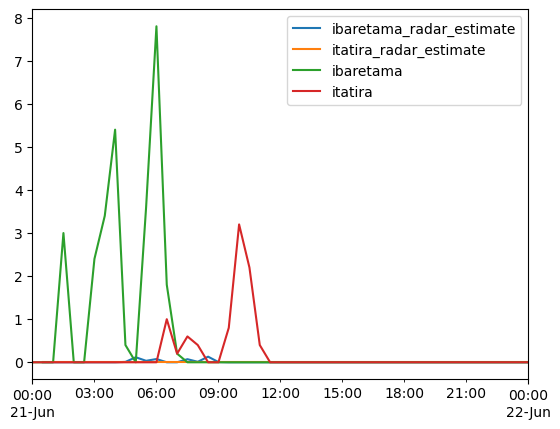

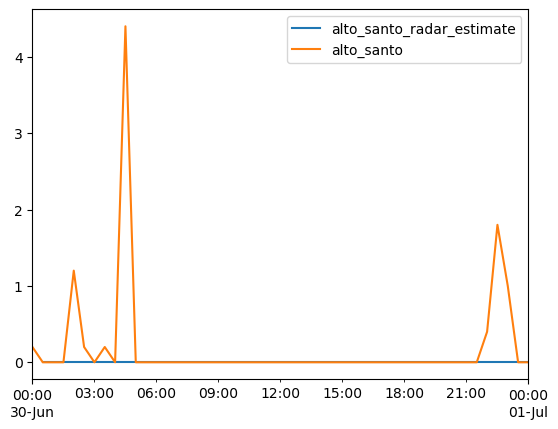

In [ ]:
for df in dfs_30min:
    df_clean  = df.copy()
    

In [ ]:


for df in dfs_30min:
    display(df.head())
    cols = df.columns
    sts = [i for i in cols if "radar" in i]
    df.rename(columns={i: f"{i[:-15]}" for i in sts}, inplace=True)
    display(df)
    break

,santa_quiteria_radar_estimate,alto_santo_radar_estimate,santa_quiteria_gauges_gauges_gauge_measurement_gauge_measurement,alto_santo_gauges_gauges_gauge_measurement_gauge_measurement
2023-04-02 00:00:00,NaN,NaN,0.0,0.0
2023-04-02 00:30:00,0.0,0.0,0.2,0.0
2023-04-02 01:00:00,0.0,0.0,0.0,0.0
2023-04-02 01:30:00,0.0,0.0,0.0,0.0
2023-04-02 02:00:00,0.0,0.0,0.0,0.0


,santa_quiteria,alto_santo,santa_quiteria_gauges_gauges_gauge_measurement_gauge_measurement,alto_santo_gauges_gauges_gauge_measurement_gauge_measurement
2023-04-02 00:00:00,NaN,NaN,0.0,0.0
2023-04-02 00:30:00,0.000000,0.0,0.2,0.0
2023-04-02 01:00:00,0.000000,0.0,0.0,0.0
2023-04-02 01:30:00,0.000000,0.0,0.0,0.0
2023-04-02 02:00:00,0.000000,0.0,0.0,0.0
2023-04-02 02:30:00,0.000000,0.0,0.0,0.0
2023-04-02 03:00:00,0.000000,0.0,0.0,0.0
2023-04-02 03:30:00,0.000000,0.0,0.0,0.0
2023-04-02 04:00:00,0.000000,0.0,0.0,0.0
2023-04-02 04:30:00,0.000000,0.0,0.0,0.0


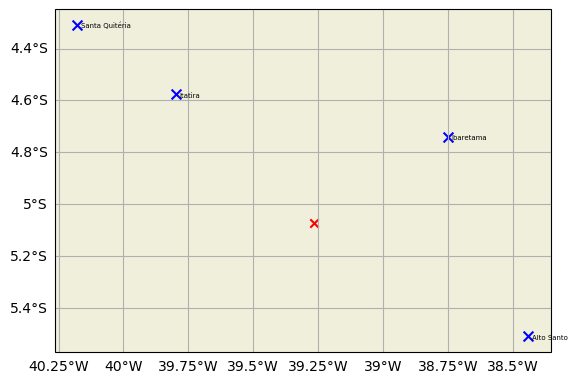

In [60]:
gvis.plot_simple_map()

gvis.plot_gauge_network(gauges.metadata.loc[stations_for_calibration], display_names=True)
ax = plt.gca()
ax.scatter(lon0, lat0, marker='x', c='r')

<Axes: xlabel='datetime'>

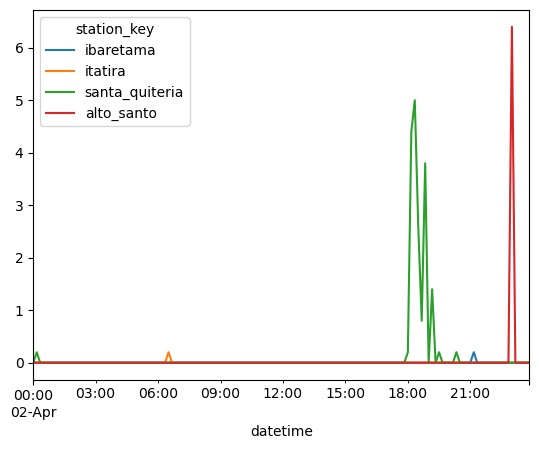

In [56]:
df_gauges.plot()

In [41]:
'''dfs_by_cols = []
for row in gauges.metadata.iterrows():
    lon, lat = row[1].lon, row[1].lat
    df_rad_at_gauge = gutils.ds_to_df_at_point(ds3, (lon, lat))
    # rename column to gauge name
    df_rad_at_gauge.rename(columns={'dBZ': f'{row[0]}'}, inplace=True)
    dfs_by_cols.append(df_rad_at_gauge)
df_gauges_from_rad = pd.concat(dfs_by_cols, axis=1)
'''
dfs_30min =[]
for date in radar_gau_2023:
    ds_rad = xr.open_dataset(df_paths_l1.loc[date].paths)
    ds_rain = l2rad.calc_rate_from_refl(ds_rad).fillna(0)
    display(ds_rad)
    dfs_by_cols = []
    for row in gauges.metadata.loc[stations_for_calibration].iterrows():
        lon, lat = row[1].lon, row[1].lat
        df_rad_at_gauge = gutils.ds_to_df_at_point(ds_rain, (lon, lat))
        # rename column to gauge name
        df_rad_at_gauge.rename(columns={'dBZ': f'{row[0]}_radar_estimate'}, inplace=True)
        dfs_by_cols.append(df_rad_at_gauge)
    df_gauges_from_rad = pd.concat(dfs_by_cols, axis=1)
    rad_estimate_30min_acc = (df_gauges_from_rad.resample('30min', label="right", closed="right").mean())*0.5
    gau_measurement_acc_30min = gauges.data.loc[date, stations_for_calibration].resample('30min', label="right", closed="right").sum()
    rad_v_gauges = pd.concat([rad_estimate_30min_acc, gau_measurement_acc_30min], axis=1)
    dfs_30min.append(rad_v_gauges)

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 162, lat: 1856, lon: 1869)
Coordinates:
  * time     (time) datetime64[ns] 1kB 2023-04-02T00:09:06 ... 2023-04-03T00:...
  * lat      (lat) float64 15kB -8.425 -8.422 -8.418 ... -1.723 -1.719 -1.715
  * lon      (lon) float64 15kB -42.64 -42.63 -42.63 ... -35.91 -35.9 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 2GB nan nan nan nan ... nan nan nan nan
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  400.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2023-04-02 00:04:42
    source_first_scan_t_f:   2023-04-02 00:13:30

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 164, lat: 1856, lon: 1869)
Coordinates:
  * time     (time) datetime64[ns] 1kB 2023-04-03T00:10:13.500000 ... 2023-04...
  * lat      (lat) float64 15kB -8.425 -8.422 -8.418 ... -1.723 -1.719 -1.715
  * lon      (lon) float64 15kB -42.64 -42.63 -42.63 ... -35.91 -35.9 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 2GB nan nan nan nan ... nan nan nan nan
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  400.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2023-04-03 00:05:48
    source_first_scan_t_f:   2023-04-03 00:14:39

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 162, lat: 1856, lon: 1869)
Coordinates:
  * time     (time) datetime64[ns] 1kB 2023-04-04T00:12:18.500000 ... 2023-04...
  * lat      (lat) float64 15kB -8.425 -8.422 -8.418 ... -1.723 -1.719 -1.715
  * lon      (lon) float64 15kB -42.64 -42.63 -42.63 ... -35.91 -35.9 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 2GB nan nan nan nan ... nan nan nan nan
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  400.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2023-04-04 00:07:54
    source_first_scan_t_f:   2023-04-04 00:16:43

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 162, lat: 1856, lon: 1869)
Coordinates:
  * time     (time) datetime64[ns] 1kB 2023-04-06T00:12:05 ... 2023-04-07T00:...
  * lat      (lat) float64 15kB -8.425 -8.422 -8.418 ... -1.723 -1.719 -1.715
  * lon      (lon) float64 15kB -42.64 -42.63 -42.63 ... -35.91 -35.9 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 2GB nan nan nan nan ... nan nan nan nan
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  400.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2023-04-06 00:07:41
    source_first_scan_t_f:   2023-04-06 00:16:29

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 162, lat: 1856, lon: 1869)
Coordinates:
  * time     (time) datetime64[ns] 1kB 2023-04-08T00:05:07 ... 2023-04-08T23:...
  * lat      (lat) float64 15kB -8.425 -8.422 -8.418 ... -1.723 -1.719 -1.715
  * lon      (lon) float64 15kB -42.64 -42.63 -42.63 ... -35.91 -35.9 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 2GB nan nan nan nan ... nan nan nan nan
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  400.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2023-04-08 00:00:43
    source_first_scan_t_f:   2023-04-08 00:09:31

...

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 159, lat: 1856, lon: 1869)
Coordinates:
  * time     (time) datetime64[ns] 1kB 2023-04-29T00:02:09.500000 ... 2023-04...
  * lat      (lat) float64 15kB -8.425 -8.422 -8.418 ... -1.723 -1.719 -1.715
  * lon      (lon) float64 15kB -42.64 -42.63 -42.63 ... -35.91 -35.9 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 2GB nan nan nan nan ... nan nan nan nan
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  400.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2023-04-29 00:00:02
    source_first_scan_t_f:   2023-04-29 00:04:17

<xarray.Dataset> Size: 4GB
Dimensions:  (time: 282, lat: 1856, lon: 1869)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2023-05-13T00:02:09.500000 ... 2023-05...
  * lat      (lat) float64 15kB -8.425 -8.422 -8.418 ... -1.723 -1.719 -1.715
  * lon      (lon) float64 15kB -42.64 -42.63 -42.63 ... -35.91 -35.9 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 4GB nan nan nan nan ... nan nan nan nan
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  400.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2023-05-13 00:00:02
    source_first_scan_t_f:   2023-05-13 00:04:17

<xarray.Dataset> Size: 4GB
Dimensions:  (time: 288, lat: 1856, lon: 1869)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2023-06-15T00:02:18 ... 2023-06-15T23:...
  * lat      (lat) float64 15kB -8.425 -8.422 -8.418 ... -1.723 -1.719 -1.715
  * lon      (lon) float64 15kB -42.64 -42.63 -42.63 ... -35.91 -35.9 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 4GB nan nan nan nan ... nan nan nan nan
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  400.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2023-06-15 00:00:02
    source_first_scan_t_f:   2023-06-15 00:04:34

<xarray.Dataset> Size: 4GB
Dimensions:  (time: 288, lat: 1856, lon: 1869)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2023-06-21T00:02:18 ... 2023-06-21T23:...
  * lat      (lat) float64 15kB -8.425 -8.422 -8.418 ... -1.723 -1.719 -1.715
  * lon      (lon) float64 15kB -42.64 -42.63 -42.63 ... -35.91 -35.9 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 4GB nan nan nan nan ... nan nan nan nan
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  400.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2023-06-21 00:00:02
    source_first_scan_t_f:   2023-06-21 00:04:34

<xarray.Dataset> Size: 4GB
Dimensions:  (time: 288, lat: 1856, lon: 1869)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2023-06-30T00:02:04 ... 2023-06-30T23:...
  * lat      (lat) float64 15kB -8.425 -8.422 -8.418 ... -1.723 -1.719 -1.715
  * lon      (lon) float64 15kB -42.64 -42.63 -42.63 ... -35.91 -35.9 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 4GB nan nan nan nan ... nan nan nan nan
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  400.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2023-06-30 00:00:02
    source_first_scan_t_f:   2023-06-30 00:04:06

<Axes: >

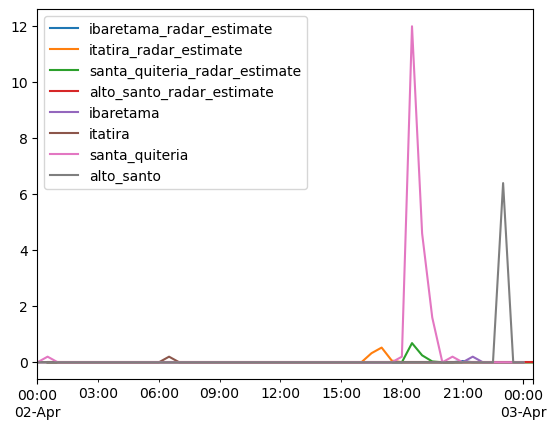

In [40]:
rad_v_gauges.plot()

<Axes: xlabel='time'>

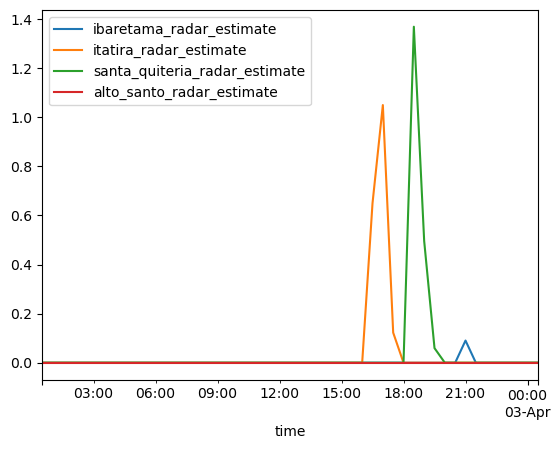

In [32]:
df_gauges_from_rad.resample('30min', label="right", closed="right").mean().plot()

<Axes: xlabel='time'>

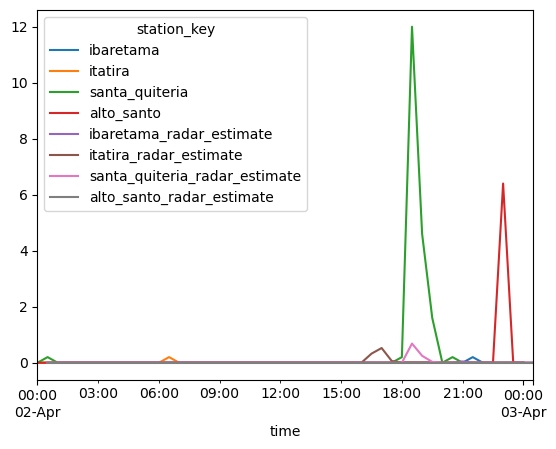

In [37]:
#df_gauges_from_rad.plot()

gauges.data.loc[date, stations_for_calibration].resample('30min', label="right", closed="right").sum().plot()
ax = plt.gca()
(df_gauges_from_rad.resample('30min', label="right", closed="right").mean()*0.5).plot(ax=ax)

<Axes: xlabel='datetime'>

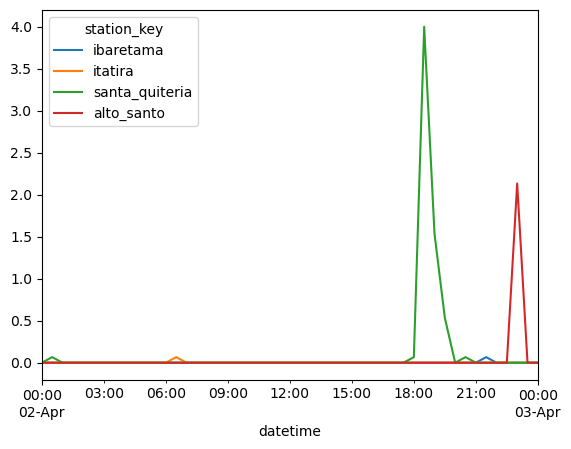

In [35]:

gauges.data.loc[date, stations_for_calibration].resample('30min', label="right", closed="right").mean().plot()

In [2]:
from pacha.utils import file_utils as futils
df_paths_l1 = futils.get_df_dates_filepaths('funceme_notebook_output/ds_out_march_july/', date_char_st=9, date_char_nd=19, date_format='%Y-%m-%d')

In [92]:
df_paths_l1

,paths
time,
2023-04-01,funceme_notebook_output/ds_out_march_july/l1_r...
2023-04-02,funceme_notebook_output/ds_out_march_july/l1_r...
2023-04-03,funceme_notebook_output/ds_out_march_july/l1_r...
2023-04-04,funceme_notebook_output/ds_out_march_july/l1_r...
2023-04-05,funceme_notebook_output/ds_out_march_july/l1_r...
...,...
2023-07-02,funceme_notebook_output/ds_out_march_july/l1_r...
2023-07-03,funceme_notebook_output/ds_out_march_july/l1_r...
2023-07-05,funceme_notebook_output/ds_out_march_july/l1_r...


In [257]:
dates_together = dates_over_150.intersection(dates_acc)

In [259]:
dates_together = [str(i.date()) for i in dates_together] 
print(dates_together)

['2023-06-15', '2023-04-03', '2023-04-08', '2023-05-13', '2023-04-02', '2023-04-15', '2023-04-04', '2023-04-26', '2023-06-21', '2023-06-30', '2023-04-29', '2023-04-06', '2023-04-16', '2023-04-27']


In [247]:
mean_acc_gauges.loc[mean_acc_gauges>5]

datetime
2023-04-02     7.084211
2023-04-03    11.378947
2023-04-04     5.578947
2023-04-05     8.377778
2023-04-06     5.011111
2023-04-08    12.922222
2023-04-15    13.022222
2023-04-16    10.311111
2023-04-26     6.077778
2023-04-27     9.944444
2023-04-29     7.488889
2023-05-05     7.200000
2023-05-13     5.152941
2023-06-15    10.694737
2023-06-21     5.315789
2023-06-30     5.066667
dtype: float64

<Axes: >

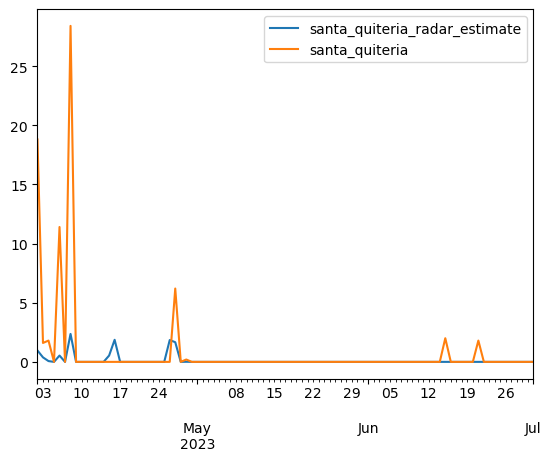

In [52]:
pd.concat(dfs_30min).groupby(pd.Grouper(freq='1D')).sum().loc[:, ['santa_quiteria_radar_estimate', 'santa_quiteria']].plot()

<Axes: xlabel='santa_quiteria_radar_estimate', ylabel='santa_quiteria'>

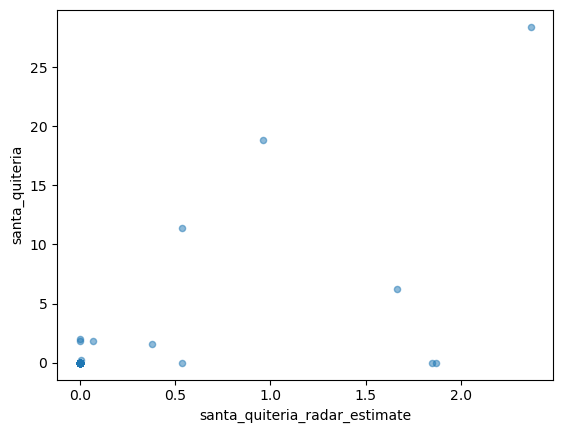

In [50]:
pd.concat(dfs_30min).groupby(pd.Grouper(freq='1D')).sum().plot.scatter(x='santa_quiteria_radar_estimate', y='santa_quiteria', alpha=0.5)

In [224]:
ds1 = open_daily_funceme(paths_df, '2023-06-21')
    

In [225]:
ds2 = to_lonlat(ds1.fillna(-100))

In [226]:
ds3 = l2rad.calc_rate_from_refl(ds2, offset=6)

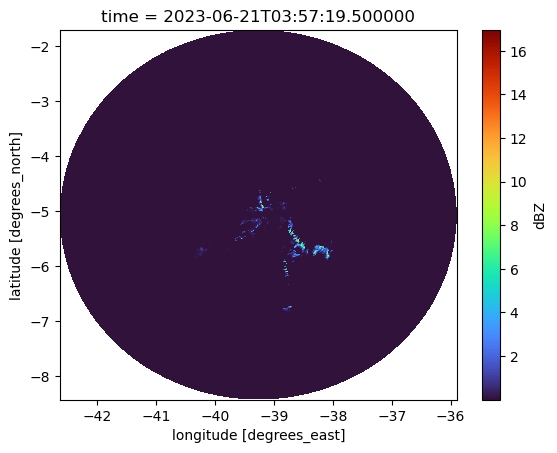

In [227]:
ds3.sel(time='2023-06-21T040000', method='nearest').dBZ.plot(cmap='turbo')

In [228]:
dfs_by_cols = []
for row in gauges.metadata.iterrows():
    lon, lat = row[1].lon, row[1].lat
    df_rad_at_gauge = gutils.ds_to_df_at_point(ds3, (lon, lat))
    # rename column to gauge name
    df_rad_at_gauge.rename(columns={'dBZ': f'{row[0]}'}, inplace=True)
    dfs_by_cols.append(df_rad_at_gauge)
df_gauges_from_rad = pd.concat(dfs_by_cols, axis=1)

In [229]:
at_10_rad = df_gauges_from_rad.groupby(pd.Grouper(freq='10min')).mean()

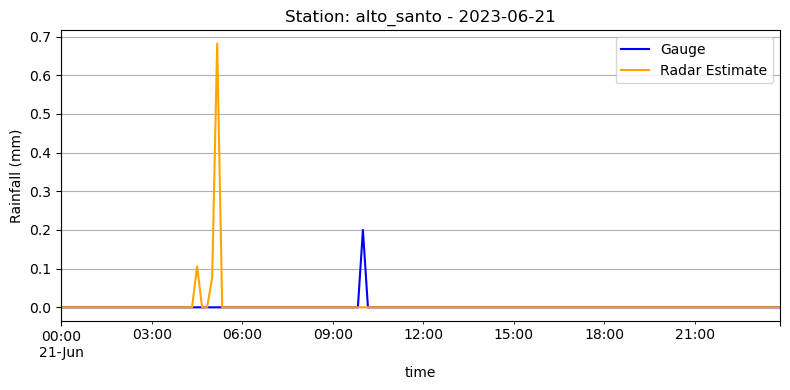

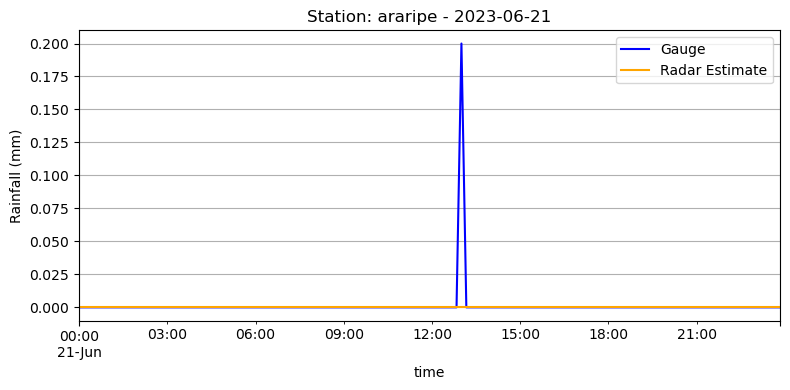

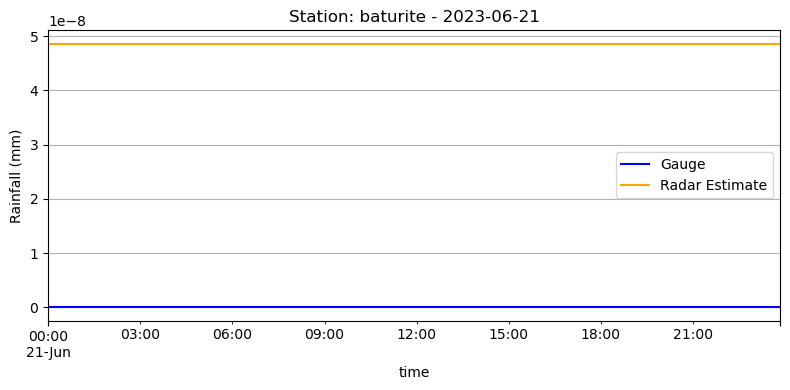

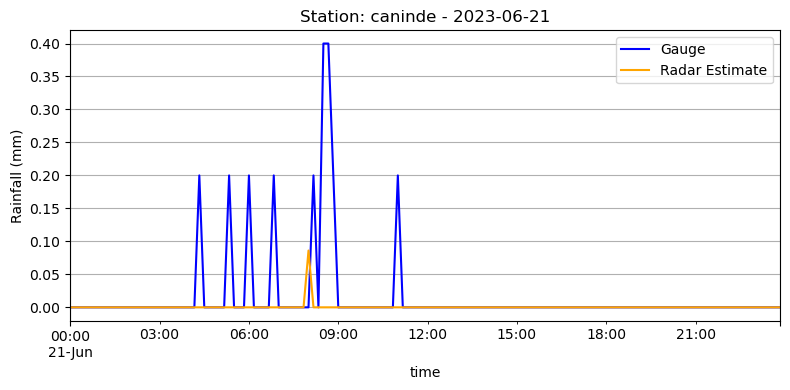

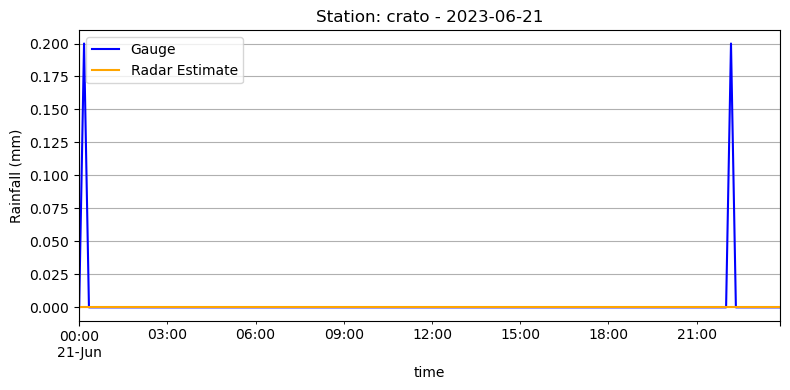

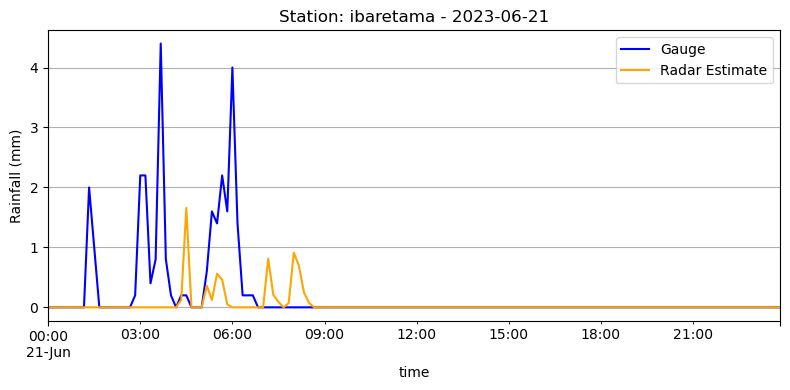

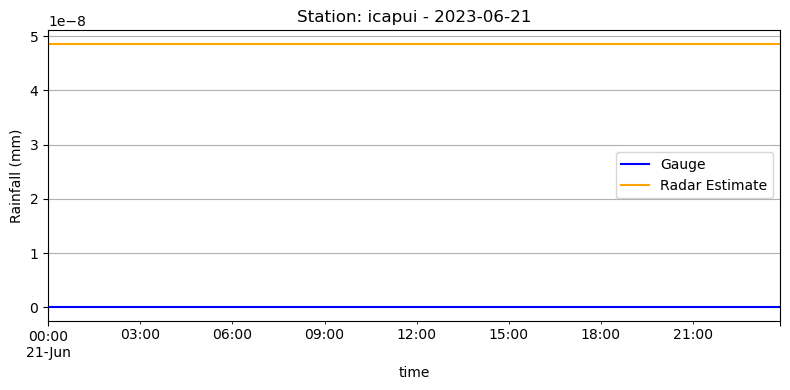

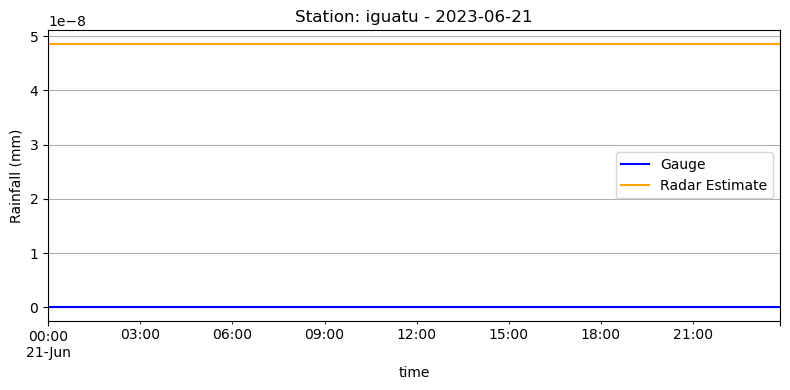

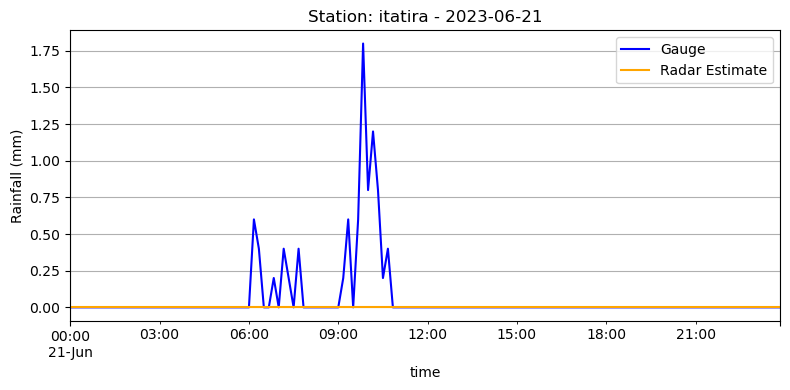

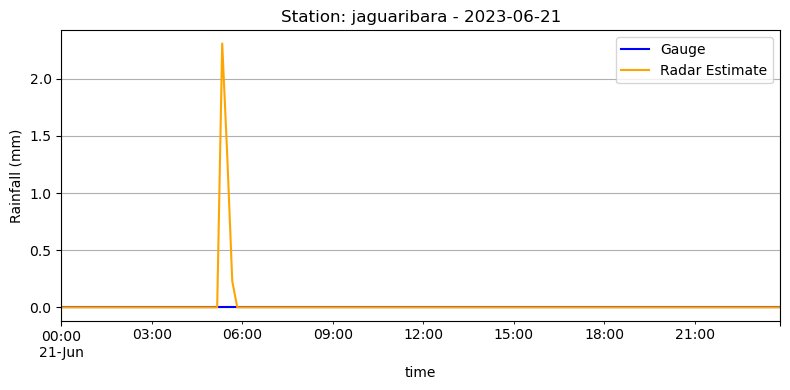

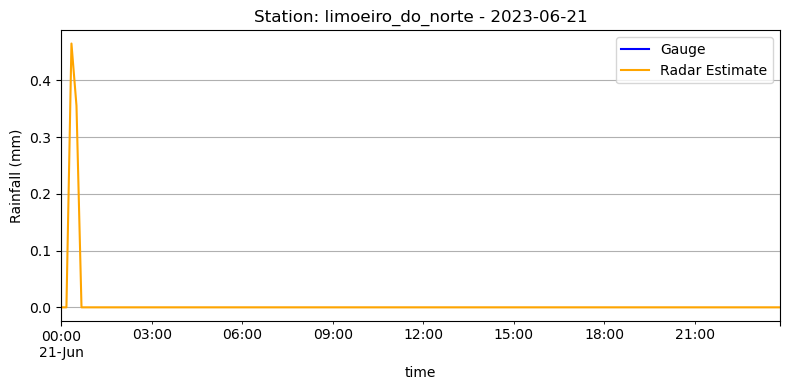

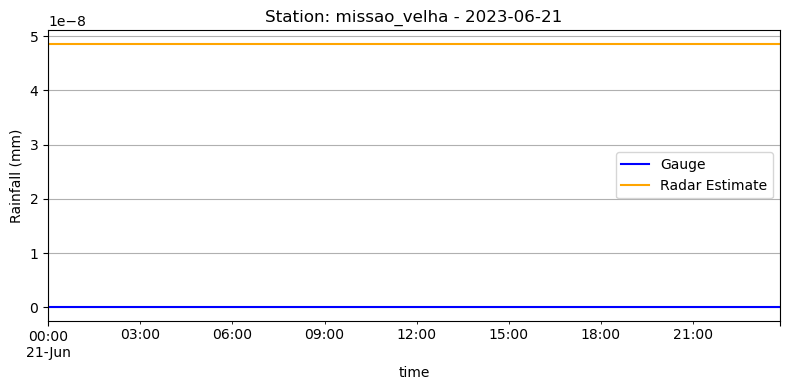

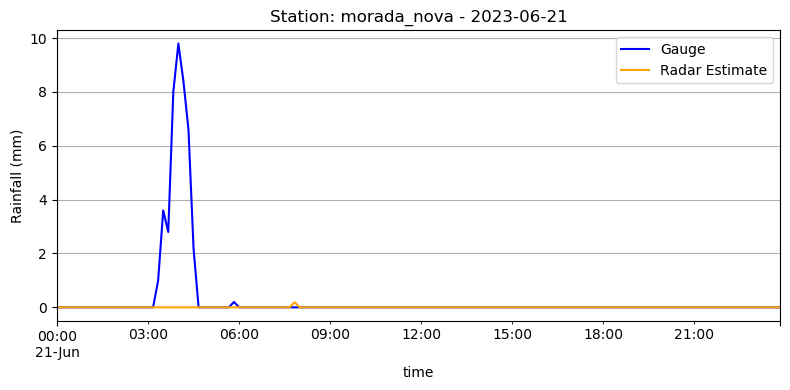

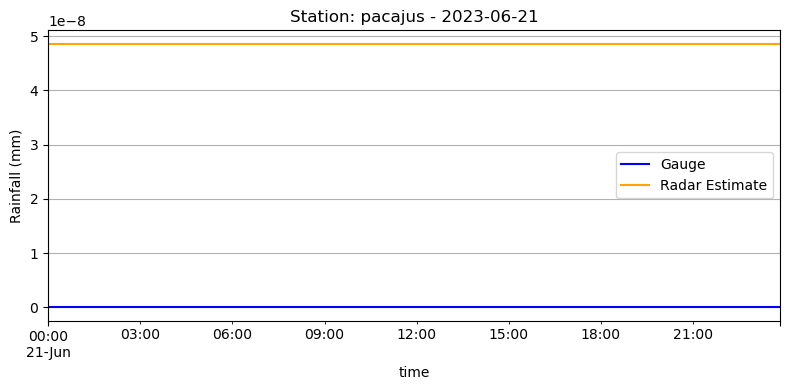

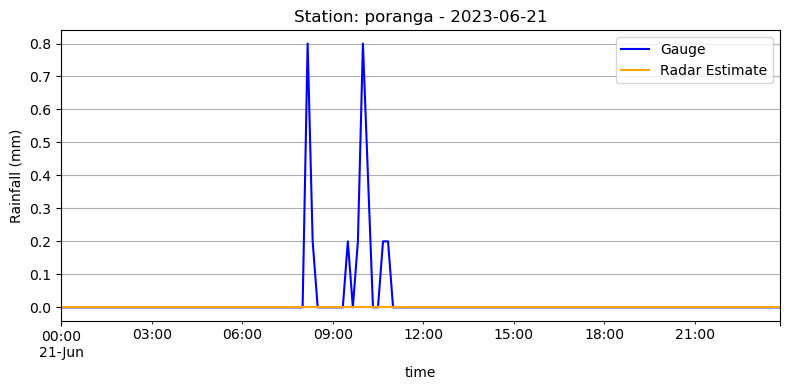

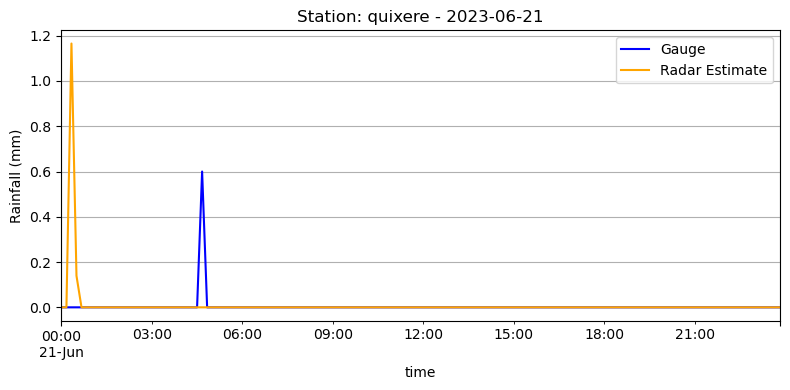

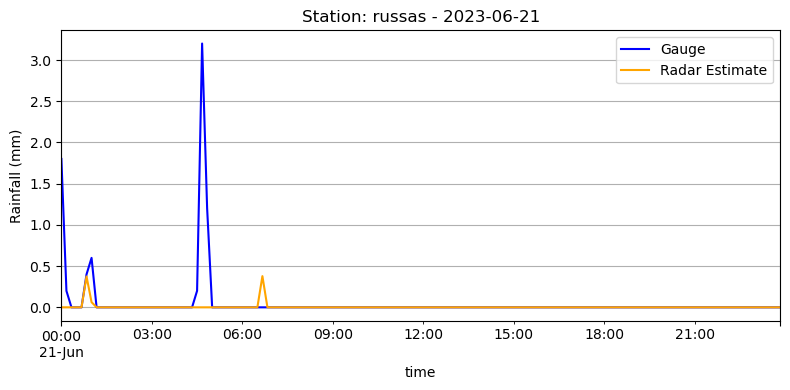

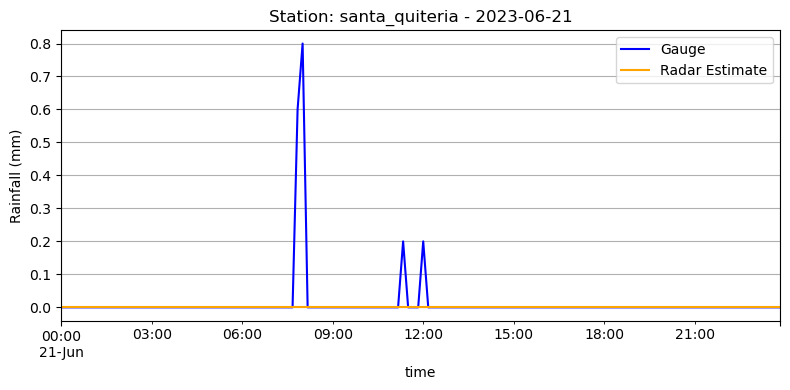

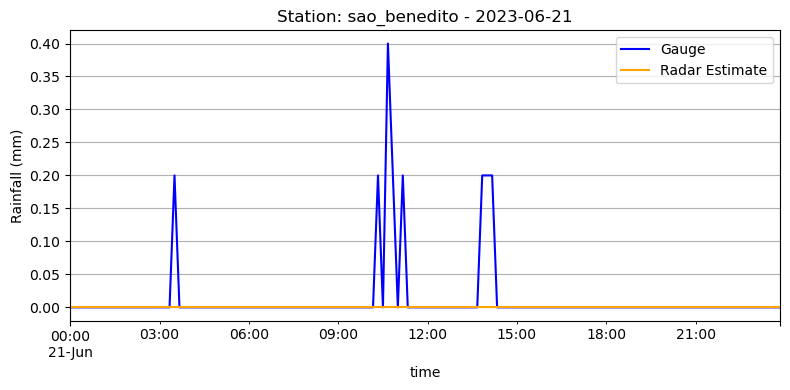

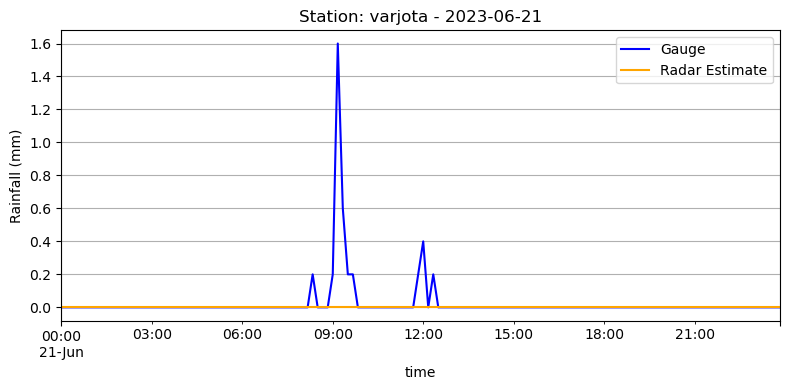

In [230]:
for station in gauges.data.columns:
    if station not in at_10_rad.columns:
        continue
    fig, ax = plt.subplots(figsize=(8, 4))
    gauges.data.loc['2023-06-21', station].plot(ax=ax, label='Gauge', color='blue')
    at_10_rad[station].plot(ax=ax, label='Radar Estimate', color='orange')
    ax.set_title(f'Station: {station} - 2023-06-21')
    ax.set_ylabel('Rainfall (mm)')
    ax.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()

In [18]:
stations_for_calibration = ['ibaretama', 'itatira', 'santa_quiteria', 'alto_santo']

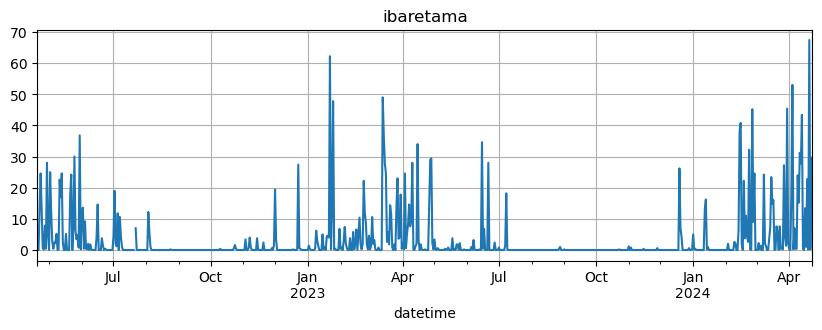

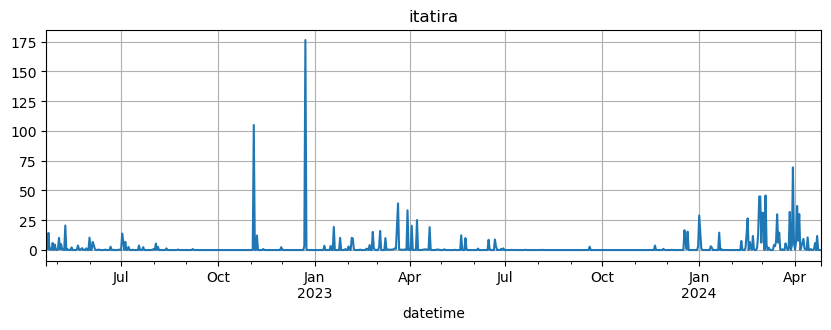

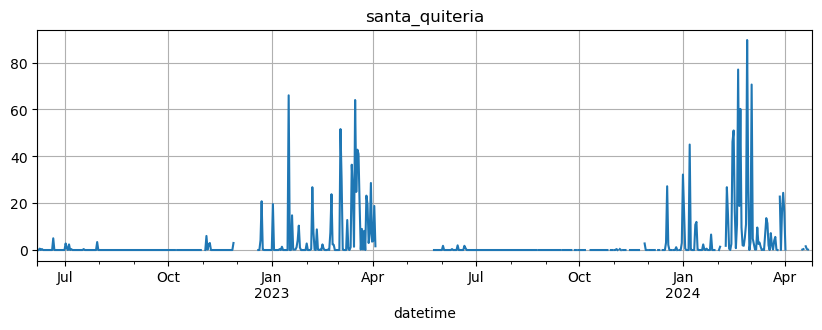

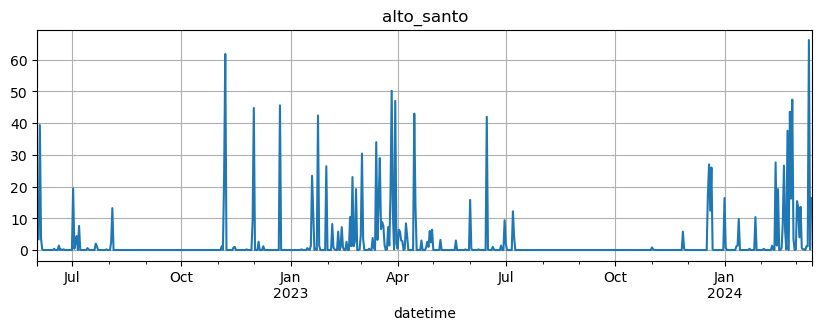

In [19]:
for station in stations_for_calibration:
    df = gauges.data.loc[:, station].dropna()
    daily_acc = df.groupby(pd.Grouper(freq='1D')).sum(min_count=140)
    daily_acc.plot(figsize=(10,3), title=f'{station}')
    ax = plt.gca()
    ax.grid()
    plt.show()


In [20]:
from pacha.visualisation import statistical as svis

<Axes: xlabel='gauge_measurement', ylabel='radar_estimate'>

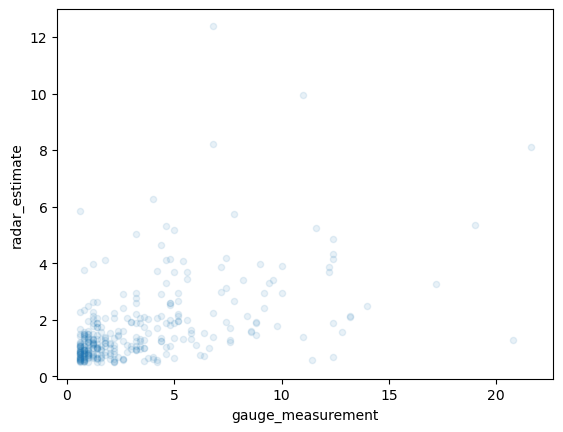

In [107]:
pd.concat(dfs).loc[((pd.concat(dfs) > 0.5).astype(int).sum(axis=1))>=2].plot.scatter('gauge_measurement', 'radar_estimate', alpha=0.1)

rvalue 0.6298932195678095
slope 0.25691225790673466
intercept 0.04910029628284786
pvalue 0.0
std_err 0.004281624662397091


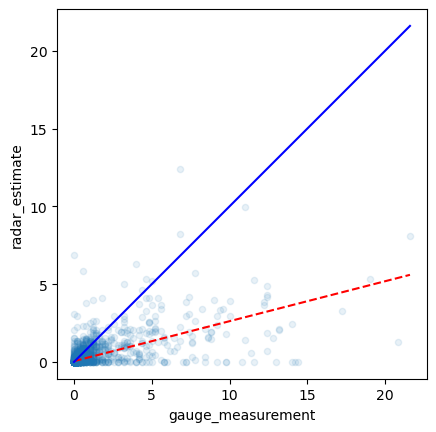

In [93]:
pd.concat(dfs).plot.scatter('gauge_measurement', 'radar_estimate', alpha=0.1)
svis.plot_fit(pd.concat(dfs).gauge_measurement, pd.concat(dfs).radar_estimate, print_vals=True)
ax = plt.gca()
ax.set_aspect('equal')

(0.0, 5.0)

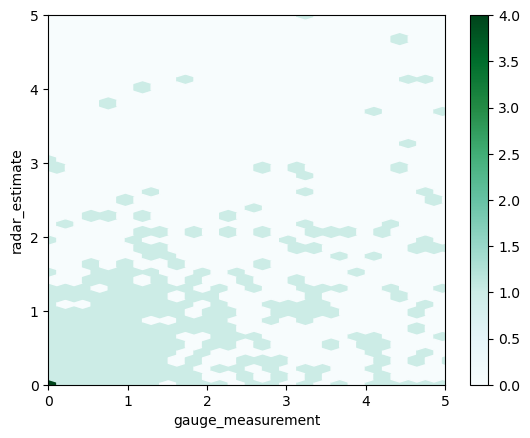

In [99]:
pd.concat(dfs).plot.hexbin('gauge_measurement', 'radar_estimate', bins=5)
ax = plt.gca()
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)

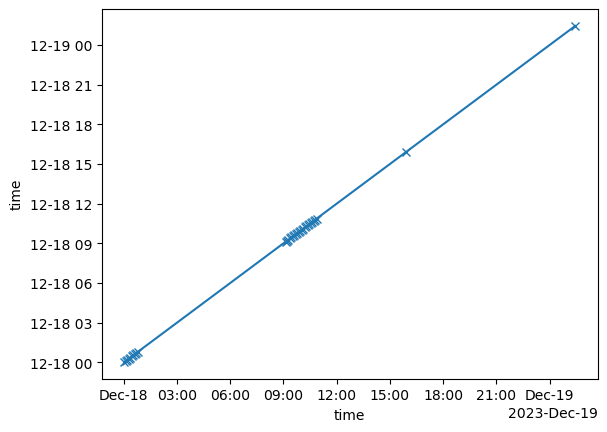

In [67]:
ds.time.plot(marker='x')

In [39]:
dates_over_150

{Timestamp('2023-04-01 00:00:00'),
 Timestamp('2023-04-02 00:00:00'),
 Timestamp('2023-04-03 00:00:00'),
 Timestamp('2023-04-04 00:00:00'),
 Timestamp('2023-04-06 00:00:00'),
 Timestamp('2023-04-07 00:00:00'),
 Timestamp('2023-04-08 00:00:00'),
 Timestamp('2023-04-09 00:00:00'),
 Timestamp('2023-04-10 00:00:00'),
 Timestamp('2023-04-11 00:00:00'),
 Timestamp('2023-04-12 00:00:00'),
 Timestamp('2023-04-13 00:00:00'),
 Timestamp('2023-04-14 00:00:00'),
 Timestamp('2023-04-15 00:00:00'),
 Timestamp('2023-04-16 00:00:00'),
 Timestamp('2023-04-17 00:00:00'),
 Timestamp('2023-04-19 00:00:00'),
 Timestamp('2023-04-20 00:00:00'),
 Timestamp('2023-04-22 00:00:00'),
 Timestamp('2023-04-23 00:00:00'),
 Timestamp('2023-04-24 00:00:00'),
 Timestamp('2023-04-25 00:00:00'),
 Timestamp('2023-04-26 00:00:00'),
 Timestamp('2023-04-27 00:00:00'),
 Timestamp('2023-04-28 00:00:00'),
 Timestamp('2023-04-29 00:00:00'),
 Timestamp('2023-04-30 00:00:00'),
 Timestamp('2023-05-10 00:00:00'),
 Timestamp('2023-05-

ibaretama


np.float64(2305.8)

itatira


np.float64(1520.1999999999998)

santa_quiteria


np.float64(1925.3999999999999)

alto_santo


np.float64(1486.4)

67


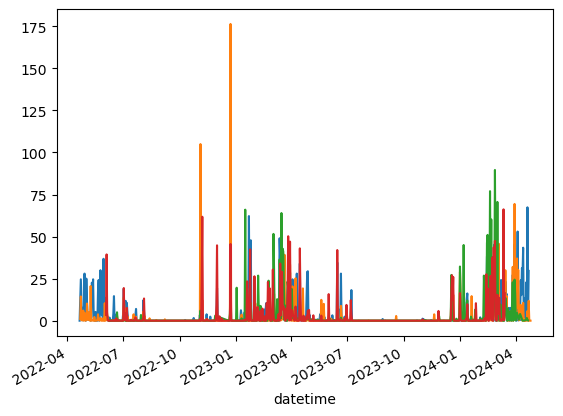

In [44]:
threshold = 10
dict_dates_per_gauge = {}
for col in stations_for_calibration:
    if gauges.metadata.loc[col, 'distance_to_point'] > 150:
        continue
    print(col)
    df = gauges.data.loc[:, col].dropna()
    display(df.sum())
    daily_acc = (df.groupby(pd.Grouper(freq='1D')).sum(min_count=140)).dropna()
    daily_acc.plot()
    dates_over_threshold = daily_acc.loc[(daily_acc > threshold)]
    dict_dates_per_gauge[col] = [str(i.date()) for i in dates_over_threshold.index]

all_dates = sorted({
    date
    for dates in dict_dates_per_gauge.values()
    for date in dates
})

sel_dates = [i for i in all_dates if i in [str(i) for i in list(set([j.date() for j in paths_df.index]))]]

print(len(sel_dates))

In [47]:
sel_dates

['2023-04-02',
 '2023-04-03',
 '2023-04-07',
 '2023-04-08',
 '2023-04-10',
 '2023-04-15',
 '2023-04-16',
 '2023-04-20',
 '2023-04-26',
 '2023-04-27',
 '2023-04-28',
 '2023-05-20',
 '2023-06-01',
 '2023-06-15',
 '2023-06-21',
 '2023-07-08',
 '2023-12-18',
 '2023-12-19',
 '2024-01-01',
 '2024-01-02',
 '2024-01-07',
 '2024-01-12',
 '2024-01-13',
 '2024-01-20',
 '2024-01-27',
 '2024-02-09',
 '2024-02-10',
 '2024-02-13',
 '2024-02-14',
 '2024-02-15',
 '2024-02-16',
 '2024-02-18',
 '2024-02-19',
 '2024-02-20',
 '2024-02-21',
 '2024-02-23',
 '2024-02-25',
 '2024-02-26',
 '2024-02-27',
 '2024-02-28',
 '2024-03-01',
 '2024-03-02',
 '2024-03-03',
 '2024-03-04',
 '2024-03-05',
 '2024-03-08',
 '2024-03-12',
 '2024-03-14',
 '2024-03-15',
 '2024-03-16',
 '2024-03-17',
 '2024-03-27',
 '2024-03-29',
 '2024-03-30',
 '2024-03-31',
 '2024-04-03',
 '2024-04-04',
 '2024-04-05',
 '2024-04-09',
 '2024-04-10',
 '2024-04-11',
 '2024-04-12',
 '2024-04-13',
 '2024-04-16',
 '2024-04-18',
 '2024-04-20',
 '2024-04-

In [ ]:


grid_checks = check_radar_grids(xrs)
display(grid_checks)

assert grid_checks.to_numpy().all(), (
    "Some radar grids differ. Inspect the False entries "
    "before reusing the first dataset's mapping."
)

print(f"All {len(xrs)} datasets share the same geographic grid.")

,same_layout,same_xlon,same_ylat
dataset,,,
0,True,True,True
1,True,True,True
2,True,True,True
3,True,True,True
4,True,True,True
...,...,...,...
330,True,True,True
331,True,True,True
332,True,True,True


All 335 datasets share the same geographic grid.
